<a href="https://colab.research.google.com/github/meghanath272005/Digital-Kavach-AI/blob/main/digital_kavach_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Digital Kavach AI - Google Colab project
**One Verified Digital Identity for Safer Social Media** - Team SHELD NETWORK (HSC|AP|00132)

> **Demonstration project.** Not a certified security product. Nothing here contacts Aadhaar, DigiLocker or any social
> media platform. Every result says whether it is *machine learning*, *rule-based*, or *simulated*.

## How to run
1. Open this file in Google Colab (**File > Upload notebook**).
2. Click **Runtime > Run all** (or run cells top to bottom with Shift+Enter). Total time is about 2-4 minutes.
3. When asked, either let the dataset download automatically or upload the file shown in Step 4.
4. Use the interactive section (Step 12) to test your own message, profile and image.

## What the project does (simple English)
| Step | Feature | Type |
|---|---|---|
| 4-7 | **Scam-message classifier**: learns from thousands of real labelled SMS messages | **Real machine learning** (TF-IDF + Logistic Regression, compared with Naive Bayes) |
| 8 | **Hybrid scam checker**: ML score + transparent rules (OTP, urgency, fake links, prizes...) | ML + rule-based |
| 9 | **Fake-profile risk checker** | Rule-based (explainable points) |
| 10 | **Image analysis**: metadata, Error Level Analysis, face regions | Real image processing. **Not a deepfake detector** |
| 11 | **Identity and account-linking demo**, **impersonation reports** (SQLite) | Simulated identity + real pseudonym maths + local database |

## Step 1 - Install libraries
Colab already has most of them. This cell installs anything missing (OpenCV headless build, ipywidgets). It is quiet unless something fails.

In [1]:
import sys, subprocess
def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
try:
    import cv2, PIL, sklearn, pandas, matplotlib, seaborn, numpy
except ImportError:
    _pip("opencv-python-headless", "pillow", "scikit-learn", "pandas", "matplotlib", "seaborn", "numpy")
try:
    import ipywidgets
except ImportError:
    try:
        _pip("ipywidgets")
    except Exception:
        print("ipywidgets not installed - Step 12 will fall back to text prompts.")
print("Libraries ready.")

Libraries ready.


## Step 2 - Imports and settings
Loads the libraries, fixes the random seed (so results are reproducible) and creates a folder for our own modules.

In [2]:
import io, os, re, json, sqlite3, hashlib, hmac, secrets, zipfile, urllib.request, base64, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import cv2
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, auc, classification_report)
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
os.makedirs("kavach", exist_ok=True)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
Path("kavach/__init__.py").write_text("")
print("Setup complete. Python", sys.version.split()[0])

Setup complete. Python 3.13.18


## Step 3 - Load the rule engines and image analyser
The next three cells write our tested analysis modules into the `kavach/` folder (the same code used by the web prototype):
* `scam_rules` - transparent scam-message rules and link inspection
* `profile_rules` - fake-profile risk rules
* `image_forensics` - metadata, Error Level Analysis, face regions, synthetic sample image

In [3]:
%%writefile kavach/scam_rules.py
"""Scam-message detector - TRANSPARENT RULES ONLY (no ML, no LLM).

Links found in a message are only *described* (defanged). They are never opened,
resolved or fetched by this code.
"""
import re
from urllib.parse import urlparse

DISCLAIMER = "Risk assessment is preliminary and may be incorrect. Rules mainly cover English and some Hinglish."

SENSITIVE = r"(otp|one[- ]time (password|pin|code)|password|passcode|\bpin\b|cvv|cvc|mpin|upi pin|secret code|verification code)"
REQUEST_VERB = r"(share|send|tell|give|provide|enter|reply(?: with)?|forward|confirm|verify|submit|read out|type)"
NEGATION = re.compile(r"(do not|don't|dont|never|not to|won't ask|will never ask|nobody should)\W+(\w+\W+){0,3}$", re.I)

ORGS = [
    "sbi", "state bank", "hdfc", "icici", "axis bank", "kotak", "punjab national bank", "rbi",
    "reserve bank", "uidai", "aadhaar", "aadhar", "income tax", "it department", "police", "cbi",
    "customs", "trai", "department of telecom", "fedex", "dhl", "blue ?dart", "electricity board",
    "amazon", "flipkart", "paytm", "phonepe", "npci", "epfo", "irctc", "microsoft", "customer care",
    "cyber ?crime", "narcotics",
]
OFFICIAL_DOMAINS = {
    "sbi": ["sbi.co.in", "onlinesbi.sbi"], "hdfc": ["hdfcbank.com"], "icici": ["icicibank.com"],
    "amazon": ["amazon.in", "amazon.com"], "flipkart": ["flipkart.com"], "paytm": ["paytm.com"],
    "phonepe": ["phonepe.com"], "irctc": ["irctc.co.in"], "uidai": ["uidai.gov.in"],
    "rbi": ["rbi.org.in"], "epfo": ["epfindia.gov.in"],
}
SHORTENERS = {"bit.ly", "tinyurl.com", "t.co", "goo.gl", "is.gd", "cutt.ly", "rb.gy", "shorturl.at",
              "ow.ly", "tiny.cc", "rebrand.ly", "wa.me"}
SUSPICIOUS_TLDS = {"xyz", "top", "click", "icu", "tk", "ml", "ga", "cf", "gq", "buzz", "cyou", "work",
                   "rest", "support", "zip", "mov", "sbs", "cfd"}
COMMON_TLDS = "ly|gl|cc|com|in|net|org|co|info|xyz|top|click|icu|tk|ml|ga|cf|gq|buzz|cyou|work|rest|support|me|io|link|live|online|site|shop|sbs|cfd"
URL_RE = re.compile(
    rf"(https?://[^\s<>\"']+|www\.[^\s<>\"']+|\b[a-z0-9][a-z0-9-]*(?:\.[a-z0-9-]+)*\.(?:{COMMON_TLDS})(?:/[^\s<>\"']*)?(?![a-z0-9@]))",
    re.I,
)
EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+(\.[\w-]+)+")


def _defang(url: str) -> str:
    return url.replace("http", "hxxp", 1).replace(".", "[.]")


def _rule(rid, title, points, explanation, evidence, kind="rule"):
    sev = "high" if points >= 25 else "medium" if points >= 15 else "low"
    return {"id": rid, "title": title, "points": points, "severity": sev,
            "explanation": explanation, "evidence": evidence[:5]}


def _not_negated(text: str, match: re.Match) -> bool:
    return not NEGATION.search(text[max(0, match.start() - 40):match.start()])


def _requests(text, noun_pattern):
    out = []
    pat = re.compile(rf"\b{REQUEST_VERB}\b\W+(?:\w+\W+){{0,5}}?{noun_pattern}", re.I)
    for m in pat.finditer(text):
        if _not_negated(text, m):
            out.append(m.group(0))
    return out


def analyse_links(text):
    links, seen = [], set()
    for m in URL_RE.finditer(text):
        raw = m.group(0).rstrip(".,);:!?")
        if EMAIL_RE.fullmatch(raw) or raw.lower() in seen:
            continue
        seen.add(raw.lower())
        candidate = raw if re.match(r"https?://", raw, re.I) else "http://" + raw
        try:
            p = urlparse(candidate)
            host = (p.hostname or "").lower()
        except ValueError:
            continue
        if not host or "." not in host:
            continue
        labels = host.split(".")
        reg = ".".join(labels[-2:])
        tld = labels[-1]
        reasons = []
        if raw.lower().startswith("http://"):
            reasons.append("uses unencrypted http")
        if re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", host):
            reasons.append("uses a raw IP address")
        if "xn--" in host:
            reasons.append("uses an encoded (punycode) domain")
        if reg in SHORTENERS:
            reasons.append("is a link shortener that hides the destination")
        if tld in SUSPICIOUS_TLDS:
            reasons.append(f"ends in .{tld}, an extension frequently abused in scams")
        if host.count("-") >= 2:
            reasons.append("has many hyphens, common in fake 'verification' sites")
        for brand, domains in OFFICIAL_DOMAINS.items():
            if brand in host and reg not in domains:
                reasons.append(f"mentions '{brand}' but is not that organisation's known domain ({domains[0]})")
                break
        links.append({"display": _defang(raw), "host_defanged": host.replace(".", "[.]"), "reasons": reasons})
    return links


def validate(data: dict):
    text = str(data.get("message", ""))
    if not text.strip():
        return None, {"message": "Paste the message you want to check."}
    if len(text) > 5000:
        return None, {"message": "Keep the message under 5,000 characters."}
    return text.strip(), {}


def analyse(text: str) -> dict:
    low = text.lower()
    findings = []

    # 1. OTP / password requests (ignores 'never share your OTP' style warnings)
    reqs = _requests(low, SENSITIVE)
    if reqs:
        findings.append(_rule("R1", "Asks for an OTP, PIN or password", 40,
            "No genuine bank, government office or delivery company asks you to share OTPs, PINs or passwords "
            "by message or call.", reqs))
    elif re.search(SENSITIVE, low):
        findings.append({"id": "R1i", "title": "Mentions OTP / PIN / password but does not appear to ask for it", "points": 0,
            "severity": "info", "explanation": "Genuine alerts often say 'never share your OTP'. Still confirm the sender.",
            "evidence": [re.search(SENSITIVE, low).group(0)]})

    # 2. Urgency
    urg_txt = [m.group(0) for m in re.finditer(
        r"\burgent(ly)?\b|immediately|within \d+\s*(hours?|hrs?|minutes?|mins?)|last chance|act now|"
        r"expires? (today|soon|tonight)|final notice|(account|card|sim|number|service)\W+(\w+\W+){0,3}"
        r"(blocked|suspended|closed|deactivated|disconnected)|today only|\basap\b|turant|jaldi", low)]
    if urg_txt:
        findings.append(_rule("R2", "Creates urgency or threatens to block something", 15,
            "Scammers rush you so you do not stop to verify.", urg_txt))

    # 3. Payment requests
    pay = [m.group(0) for m in re.finditer(
        r"\b(pay|transfer|send|deposit|remit|clear)\b\W+(?:\w+\W+){0,4}?(rs\.?|₹|inr|\$|usd|money|amount|fee|charges?|payment)"
        r"|(processing|registration|clearance|customs|delivery|release|refundable|security) (fee|charges?|deposit)"
        r"|gift cards?|scan (this |the )?qr|enter (your )?(upi )?pin to receive", low)
        if _not_negated(low, m)]
    if pay:
        findings.append(_rule("R3", "Requests a payment or fee", 25,
            "Upfront fees, gift cards and 'scan this QR / enter PIN to receive money' are classic fraud steps. "
            "You never enter a PIN to receive money.", pay))

    # 4. Links
    links = analyse_links(text)
    if links:
        extra = sum(1 for l in links if l["reasons"])
        pts = min(35, 10 + 12 * extra) if extra else 10
        findings.append(_rule("R4", "Contains link(s) - not opened by this tool" if not extra
                              else "Contains suspicious-looking link(s) - not opened by this tool", pts,
            "Scam links imitate banks and delivery firms to steal logins. This tool only inspects the text of the "
            "link; it never visits it.", [f"{l['display']}: {', '.join(l['reasons']) or 'no technical red flags in the text'}" for l in links]))

    # 5. Prizes
    prize = [m.group(0) for m in re.finditer(
        r"you(?:'ve| have)? (won|been selected|are selected)|lucky (draw|winner)|congratulations|lottery|jackpot|"
        r"\bprize\b|free (gift|iphone|recharge|laptop)|cashback of|\bkbc\b|inaam|you are (the )?winner", low)]
    if prize:
        findings.append(_rule("R5", "Unrealistic prize or reward claim", 30,
            "You cannot win a contest you never entered. Prizes that need a 'fee' or 'verification' are scams.", prize))

    # 6. Confidential-information requests
    conf = _requests(low, r"(aadhaar|aadhar|pan( card| number)?|card number|account number|bank details|date of birth|dob|selfie|photo id|passport|login (id|details))")
    if not conf:
        conf = [m.group(0) for m in re.finditer(r"(update|verify|complete) (your )?(kyc|aadhaar|pan)", low) if _not_negated(low, m)]
    if conf:
        findings.append(_rule("R6", "Asks for confidential or identity information", 30,
            "Requests to 'update KYC', or to send Aadhaar, PAN or card details by message are a common route to identity theft.", conf))

    # 7. Impersonation of official organisations
    orgs = []
    for o in ORGS:
        m = re.search(rf"\b{o}\b", low)
        if m:
            orgs.append(m.group(0))
    claims = re.search(r"your (kyc|parcel|package|sim)\b|kyc (is |has |was )?(expired|pending|suspended|incomplete)", low)
    if orgs and (claims or links or reqs or pay or conf or urg_txt):
        findings.append(_rule("R7", "May be impersonating an official organisation", 20,
            "The message names an organisation and also pressures or asks you to act. Anyone can type a bank's "
            "name - contact the organisation using the number on its official website or your card.", sorted(set(orgs))))
    elif orgs:
        findings.append({"id": "R7i", "title": "Mentions an organisation (no suspicious request found)", "points": 0,
            "severity": "info", "explanation": "Naming a company is not suspicious by itself.", "evidence": sorted(set(orgs))[:5]})

    # 8. Extra patterns
    threat = [m.group(0) for m in re.finditer(
        r"digital arrest|arrest warrant|case (has been )?registered against you|parcel (contains|has been seized|seized)|"
        r"legal action|court notice|narcotics|money laundering", low)]
    if threat:
        findings.append(_rule("R8", "Threat of arrest or legal action", 25,
            "'Digital arrest' does not exist. Police and courts do not demand payment or video calls to avoid arrest.", threat))
    remote = [m.group(0) for m in re.finditer(r"anydesk|teamviewer|quick ?support|rustdesk|screen ?shar(e|ing)|install (this |the )?(app|apk)|\.apk\b", low)]
    if remote:
        findings.append(_rule("R9", "Asks you to install an app or share your screen", 25,
            "Remote-access apps let a scammer see your screen and approve payments.", remote))
    job = [m.group(0) for m in re.finditer(r"work from home|part[- ]time job|earn\s*(rs\.?|₹)?\s*\d[\d,]*\s*(per|a|/)\s*day|like and subscribe|task (based )?(job|work)", low)]
    if job:
        findings.append(_rule("R10", "Easy-money job offer", 20,
            "Unsolicited 'earn daily' jobs that ask for a deposit or tasks are common advance-fee scams.", job))

    score = min(100, sum(f["points"] for f in findings))
    flagged = [f for f in findings if f["points"] > 0]
    if len(text) < 25 and not flagged:
        category = "Inconclusive"
    elif score >= 40:
        category = "High"
    elif score >= 15:
        category = "Medium"
    else:
        category = "Low"

    return {
        "category": category,
        "score": score,
        "thresholds": {"low": "0-14", "medium": "15-39", "high": "40 and above"},
        "findings": sorted(findings, key=lambda f: -f["points"]),
        "links": links,
        "recommendations": _recommendations(category, flagged, bool(links)),
        "method": {"type": "rule-based", "ml_or_llm_used": False,
                   "summary": "Keyword and pattern rules written by the team. No machine-learning model or LLM "
                              "reads your message. Text is not stored."},
        "limitations": [
            "Rules can miss new scam wording, other languages and images or voice notes.",
            "Rules can also flag genuine messages that happen to use similar words.",
        ],
        "disclaimer": DISCLAIMER,
    }


def _recommendations(category, flagged, has_links):
    ids = {f["id"] for f in flagged}
    recs = []
    if category == "Inconclusive":
        recs.append("The message is too short to judge. Paste the full text, including any links.")
    if has_links:
        recs.append("Do not tap or open the link. If you think the message is real, type the organisation's website address yourself.")
    if "R1" in ids:
        recs.append("Never share an OTP, PIN or password with anyone, even if they say they are from your bank.")
    if ids & {"R3", "R10"}:
        recs.append("Do not pay any fee to receive a prize, refund, loan or job. Genuine ones do not ask for it.")
    if ids & {"R7", "R6", "R8"}:
        recs.append("Call the organisation on the number printed on your card, bill or official website - not the number in the message.")
    if "R9" in ids:
        recs.append("Do not install any app or share your screen at the sender's request.")
    if category in ("High", "Medium"):
        recs.append("If money was already sent, call the National Cyber Crime Helpline 1930 immediately and report at cybercrime.gov.in.")
        recs.append("Block the sender and keep a screenshot as evidence.")
    if category == "Low":
        recs.append("No strong warning signs were found, but that does not prove the message is safe. Verify unexpected requests.")
    return recs

Writing kavach/scam_rules.py


In [4]:
%%writefile kavach/profile_rules.py
"""Fake-profile risk checker - TRANSPARENT RULES ONLY (no machine learning).

Looks only at text the user typed in. It never opens the URL, never scrapes a
platform and has no access to any platform database.  Every rule that fires is
returned with its points and a plain-language reason.
"""
import re
from urllib.parse import urlparse

DISCLAIMER = "Risk assessment is preliminary and may be incorrect."

KNOWN_PLATFORMS = {
    "instagram.com", "facebook.com", "x.com", "twitter.com", "linkedin.com", "youtube.com",
    "threads.net", "t.me", "telegram.me", "tiktok.com", "snapchat.com", "reddit.com", "github.com",
}
SHORTENERS = {"bit.ly", "tinyurl.com", "t.co", "goo.gl", "is.gd", "cutt.ly", "rb.gy", "shorturl.at",
              "ow.ly", "tiny.cc", "rebrand.ly"}
STRONG_AUTHORITY = ["official", "verified", "customercare", "helpdesk", "support", "authorised",
                    "authorized", "govt", "realaccount"]
BRAND_TOKENS = {"sbi", "hdfc", "icici", "axisbank", "rbi", "paytm", "phonepe", "amazon", "flipkart",
                "uidai", "irctc", "npci", "epfo", "google", "microsoft", "whatsapp", "instagram",
                "facebook", "police", "incometax", "cybercrime"}

MONEY_LURES = [
    r"guaranteed (returns?|profit)", r"double your money", r"invest(ment)?\b.{0,30}\b(daily|weekly|returns?)",
    r"\bforex\b", r"\bcrypto\b", r"trading signals?", r"earn\s*(rs\.?|₹)?\s*\d[\d,]*\s*(per|a|/)\s*(day|week|hour)",
    r"work from home", r"loan (approval|offer)", r"\bgiveaway\b", r"lucky (winner|draw)", r"send money",
    r"dm (me )?(to|for) (earn|invest|win|join)",
]
OFF_PLATFORM = [r"whats\s?app", r"telegram", r"\bt\.me/", r"wa\.me/", r"\b\d{10}\b", r"\+\d{2}[\s-]?\d{8,10}"]
URGENCY = [r"\burgent(ly)?\b", r"limited time", r"act now", r"\bhurry\b", r"last chance", r"today only"]
AUTHORITY_CLAIMS = [r"official (account|page|handle)", r"\bverified\b", r"government", r"\bgovt\b",
                    r"customer (care|support)", r"support team", r"authori[sz]ed (dealer|partner|agent)",
                    r"\bbank\b"]
TAKEOVER_PATTERNS = [
    r"(old|previous|main|original) (account|profile|id) (was |got |is )?(hacked|blocked|suspended|deleted|disabled)",
    r"\bnew (account|profile|id)\b", r"\bbackup account\b", r"follow (my|this) new",
]
CONCERNING_NOTES = [
    r"asked (me )?(for )?(money|otp|payment|upi|gift cards?)", r"(send|sent|shared) (me )?(a )?(link|qr)",
    r"(copied|stolen|using) (my )?(photos?|pictures?|pics?|images?)", r"blackmail", r"threat(en|s)?",
    r"morph(ed)?", r"pretend(ing)? to be", r"claims? to be", r"impersonat",
]

USERNAME_RE = re.compile(r"^@?[A-Za-z0-9._-]{2,60}$")


# ----------------------------------------------------------------- helpers
def _levenshtein(a: str, b: str) -> int:
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def _registered_domain(host: str) -> str:
    labels = host.lower().strip(".").split(".")
    return ".".join(labels[-2:]) if len(labels) >= 2 else host.lower()


def _find(patterns, text):
    hits = []
    for p in patterns:
        m = re.search(p, text, re.I)
        if m:
            hits.append(m.group(0).strip())
    return hits


def _severity(points: int) -> str:
    if points >= 20:
        return "high"
    if points >= 10:
        return "medium"
    if points > 0:
        return "low"
    return "info"


def _finding(fid, title, points, detail, field):
    return {"id": fid, "title": title, "points": points, "severity": _severity(points),
            "detail": detail, "field": field}


def normalise_url(raw: str):
    """Returns (parsed_url_or_None, error_message_or_None). Never performs any network request."""
    raw = raw.strip()
    if not raw:
        return None, None
    if len(raw) > 500:
        return None, "Profile URL is too long (500 characters maximum)."
    if re.match(r"^[a-z][a-z0-9+.-]*:", raw, re.I) and not re.match(r"^https?://", raw, re.I):
        return None, "Only http:// or https:// profile URLs are accepted."
    if not re.match(r"^https?://", raw, re.I):
        raw = "https://" + raw
    try:
        parsed = urlparse(raw)
        host = parsed.hostname
    except ValueError:
        return None, "That does not look like a valid URL."
    if not host or "." not in host:
        return None, "That does not look like a valid URL."
    return parsed, None


def _handle_from_url(parsed):
    host = (parsed.hostname or "").lower()
    parts = [p for p in parsed.path.split("/") if p]
    if not parts:
        return None
    if host.endswith("linkedin.com"):
        return parts[1] if parts[0] in ("in", "company", "school") and len(parts) > 1 else None
    first = parts[0]
    if first.lower() in {"profile.php", "channel", "c", "user", "people", "pages", "groups", "p", "reel"}:
        return None
    return first.lstrip("@")


# --------------------------------------------------------------- validation
def validate(data: dict):
    """Returns (clean_dict, field_errors)."""
    errors, clean = {}, {}
    username = str(data.get("username", "")).strip()
    if not username:
        errors["username"] = "Enter the username or handle you want to check."
    elif not USERNAME_RE.match(username):
        errors["username"] = "Use 2-60 letters, digits, dots, underscores or hyphens (an @ prefix is fine)."
    clean["username"] = username.lstrip("@")

    clean["url_raw"] = str(data.get("url", "")).strip()
    parsed, err = normalise_url(clean["url_raw"])
    if err:
        errors["url"] = err
    clean["parsed_url"] = parsed

    for key, limit in (("description", 2000), ("notes", 2000)):
        val = str(data.get(key, "") or "").strip()
        if len(val) > limit:
            errors[key] = f"Keep this under {limit} characters."
        clean[key] = val

    for key in ("account_age_days", "followers", "following"):
        raw = data.get(key)
        if raw in (None, ""):
            clean[key] = None
            continue
        try:
            n = int(raw)
            if n < 0 or n > 1_000_000_000:
                raise ValueError
            clean[key] = n
        except (TypeError, ValueError):
            errors[key] = "Enter a whole number (0 or more)."
            clean[key] = None
    return clean, errors


# ------------------------------------------------------------------ analysis
def analyse(clean: dict) -> dict:
    findings, passed = [], []
    username = clean["username"]
    ulow = username.lower()
    unorm = re.sub(r"[^a-z0-9]", "", ulow)
    tokens = set(t for t in re.split(r"[^a-z]+", ulow) if t)
    desc, notes = clean["description"], clean["notes"]
    desc_low, notes_low = desc.lower(), notes.lower()
    parsed = clean["parsed_url"]

    # ---- username rules
    hits = [w for w in STRONG_AUTHORITY if w in unorm]
    if hits:
        findings.append(_finding("U1", "Username claims authority", 10,
            f"The username contains '{hits[0]}'. Many genuine accounts use such words, but impersonators "
            "use them to look official. Check the account against the organisation's own website.", "username"))
    if re.search(r"\d{4,}$", ulow):
        findings.append(_finding("U2", "Username ends with a long number", 10,
            "Names ending in four or more digits are often auto-generated or throw-away accounts.", "username"))
    if re.search(r"[a-z][013][a-z]", ulow):
        findings.append(_finding("U3", "Digits that look like letters inside the name", 8,
            "Swapping letters for look-alike digits (0 for o, 1 for l, 3 for e) is a common trick to copy a "
            "real name.", "username"))
    if re.search(r"[._-]{2,}|([._-].*){4,}", ulow):
        findings.append(_finding("U4", "Many separators in the username", 5,
            "Repeated dots, underscores or hyphens can be used to create a near-copy of a real handle.", "username"))
    brands = sorted(b for b in BRAND_TOKENS if b in tokens or (len(b) >= 5 and b in unorm))
    if brands:
        findings.append(_finding("U5", "Username contains a well-known organisation name", 12,
            f"The username includes '{brands[0]}'. Accounts using big names are frequently fake. "
            "Genuine ones are normally linked from the organisation's official website.", "username"))
    if not any(f["field"] == "username" for f in findings):
        passed.append("No username warning signs matched (authority words, look-alike digits, brand names).")

    # ---- URL rules
    if parsed:
        host = (parsed.hostname or "").lower()
        reg = _registered_domain(host)
        name = reg.split(".")[0]
        flagged_url = False
        if parsed.scheme != "https":
            flagged_url = True
            findings.append(_finding("L1", "Link is not secure (http)", 8,
                "Genuine major platforms use https. Treat plain http profile links with caution.", "url"))
        if "@" in (parsed.netloc or ""):
            flagged_url = True
            findings.append(_finding("L2", "Link hides the real address with '@'", 25,
                "Text before an '@' in a link can disguise where it really leads.", "url"))
        if re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", host):
            flagged_url = True
            findings.append(_finding("L3", "Link uses a raw IP address", 25,
                "Real social platforms use named domains, not numeric addresses.", "url"))
        if "xn--" in host:
            flagged_url = True
            findings.append(_finding("L4", "Link uses an encoded (punycode) domain", 25,
                "Encoded domains can display look-alike foreign characters that imitate a known site.", "url"))
        if reg in SHORTENERS:
            flagged_url = True
            findings.append(_finding("L5", "Link is a URL shortener", 20,
                "A profile link should point directly at a platform. Shorteners hide the destination.", "url"))
        elif reg not in KNOWN_PLATFORMS:
            flagged_url = True
            lookalike = None
            subst = name.replace("rn", "m").replace("0", "o").replace("1", "l").replace("vv", "w")
            for known in KNOWN_PLATFORMS:
                kn = known.split(".")[0]
                if len(kn) >= 5 and (subst == kn or 1 <= _levenshtein(name, kn) <= 2):
                    lookalike = known
                    break
            embedded = next((k for k in KNOWN_PLATFORMS
                             if len(k.split(".")[0]) >= 5 and k.split(".")[0] in host), None)
            if lookalike:
                findings.append(_finding("L6", "Domain imitates a well-known platform", 30,
                    f"'{reg}' is spelled almost like '{lookalike}'. Do not trust it.", "url"))
            elif embedded:
                findings.append(_finding("L7", "Platform name used inside a different domain", 30,
                    f"The name '{embedded.split('.')[0]}' appears in the address, but the real domain is '{reg}'.", "url"))
            else:
                findings.append(_finding("L8", "Domain is not a platform this tool recognises", 10,
                    f"'{reg}' is not in this prototype's short list of common platforms. It may simply be "
                    "a smaller site - this is a weak signal.", "url"))
        if not flagged_url:
            passed.append(f"Link points to a recognised platform domain ({reg}) over https.")
        handle = _handle_from_url(parsed)
        if handle:
            if handle.lower() != ulow:
                findings.append(_finding("C1", "Handle in the link differs from the username", 15,
                    f"You entered '{username}' but the link's handle is '{handle}'. Inconsistent details "
                    "are a warning sign (or a typo).", "url"))
            else:
                passed.append("The handle inside the link matches the username you entered.")

    # ---- description rules
    if not desc:
        findings.append(_finding("D1", "No profile description supplied", 12,
            "An empty or missing bio gives little to verify. (If you simply did not paste it, add it for a "
            "better assessment.)", "description"))
    elif len(desc) < 20:
        findings.append(_finding("D1", "Very short profile description", 6,
            "Under 20 characters gives little to verify.", "description"))
    else:
        h = _find(AUTHORITY_CLAIMS, desc_low)
        if h:
            findings.append(_finding("D2", "Description makes authority or official claims", 12,
                f"The text says '{h[0]}'. Claims like this are easy to type and should be checked elsewhere.",
                "description"))
        h = _find(MONEY_LURES, desc_low)
        if h:
            findings.append(_finding("D3", "Money-making or investment lure", 25,
                f"The text includes '{h[0]}'. Promises of easy money are the most common profile-based scam.",
                "description"))
        h = _find(OFF_PLATFORM, desc_low)
        if h:
            findings.append(_finding("D4", "Pushes contact off the platform", 10,
                "Moving the chat to WhatsApp, Telegram or a phone number is common in scams, although many "
                "genuine businesses do it too.", "description"))
        h = _find(URGENCY, desc_low)
        if h:
            findings.append(_finding("D5", "Urgency or pressure wording", 8,
                f"The text includes '{h[0]}'. Pressure to act quickly is a manipulation tactic.", "description"))
        h = _find(TAKEOVER_PATTERNS, desc_low)
        if h:
            findings.append(_finding("D6", "'My old account was hacked / this is my new account' pattern", 20,
                "Impersonators often claim the real account was lost so friends follow the fake one. Confirm "
                "through a phone call or another channel.", "description"))
        if re.search(r"https?://\S+|www\.\S+", desc_low):
            for short in SHORTENERS:
                if short in desc_low:
                    findings.append(_finding("D7", "Description contains a shortened link", 15,
                        "Shortened links hide where they lead. Do not open them from an unverified profile.", "description"))
                    break
        if not any(f["field"] == "description" for f in findings):
            passed.append("No description warning signs matched (authority claims, money lures, urgency, "
                          "off-platform contact, 'new account' stories).")

    # ---- supporting information
    age, followers, following = clean["account_age_days"], clean["followers"], clean["following"]
    if age is not None:
        if age < 7:
            findings.append(_finding("S1", "Account is less than a week old", 18,
                "Very new accounts that already claim an established identity deserve extra checking.", "account_age_days"))
        elif age < 30:
            findings.append(_finding("S1", "Account is less than a month old", 12,
                "New accounts are a weak warning sign on their own.", "account_age_days"))
        else:
            passed.append(f"Account age ({age} days) is not unusually new.")
    if followers is not None and following is not None:
        if following >= 1000 and following > 20 * max(followers, 1):
            findings.append(_finding("S2", "Follows far more accounts than follow it", 8,
                "A huge following count with almost no followers is typical of mass-follow or bot-like behaviour.",
                "following"))
    if notes:
        h = _find(CONCERNING_NOTES, notes_low)
        if h:
            findings.append(_finding("S3", "You reported concerning behaviour", 25,
                f"Your notes mention '{h[0]}'. First-hand reports of money requests, copied photos or "
                "threats are strong indicators.", "notes"))

    score = min(100, sum(f["points"] for f in findings))
    dims = sum([bool(parsed), len(desc) >= 20, len(notes) >= 10,
                any(clean[k] is not None for k in ("account_age_days", "followers", "following"))])
    if score >= 40:
        category = "High"
    elif dims < 2 and score < 40:
        category = "Inconclusive"
    elif score >= 15:
        category = "Medium"
    else:
        category = "Low"
    limited = dims < 2 and score >= 40  # high on username alone: say so
    return {
        "category": category,
        "score": score,
        "thresholds": {"low": "0-14", "medium": "15-39", "high": "40 and above"},
        "findings": sorted(findings, key=lambda f: -f["points"]),
        "checks_passed": passed,
        "inputs_considered": [k for k, v in (("username", username), ("url", bool(parsed)),
                              ("description", len(desc) >= 20), ("notes", len(notes) >= 10),
                              ("account details", dims and any(clean[k] is not None for k in
                               ("account_age_days", "followers", "following")))) if v],
        "limited_information": limited or category == "Inconclusive",
        "recommendations": _recommendations(category, findings),
        "method": {"type": "rule-based", "ml_or_llm_used": False,
                   "summary": "Fixed, published rules add points; the total decides the category. "
                              "No model, no scraping, no platform data."},
        "disclaimer": DISCLAIMER,
    }


def _recommendations(category, findings):
    ids = {f["id"] for f in findings}
    recs = []
    if category == "Inconclusive":
        recs.append("Add the profile link, bio text and anything you noticed so the checker has more to work with.")
    if category in ("High", "Medium"):
        recs.append("Do not send money, OTPs, passwords or personal documents to this account.")
        recs.append("Confirm the person or organisation through a channel you already trust (phone call, official website).")
    if ids & {"L2", "L3", "L4", "L5", "L6", "L7", "D7"}:
        recs.append("Do not open the link. Type the platform's address yourself instead.")
    if ids & {"D3", "S3"}:
        recs.append("Stop replying if money or private details were requested, and keep screenshots as evidence.")
    if "D6" in ids:
        recs.append("Ask your real contact on a call whether they really created a new account.")
    if category == "High":
        recs.append("Use the platform's 'Report' tool and consider a complaint at cybercrime.gov.in or helpline 1930.")
    if category == "Low":
        recs.append("A low result does not prove the profile is genuine. Stay careful with any request for money or data.")
    recs.append("This is a preliminary check. A risk score never proves that someone is a criminal - do not accuse anyone publicly.")
    return recs

Writing kavach/profile_rules.py


In [5]:
%%writefile kavach/image_forensics.py
"""Image checks with Pillow / NumPy / OpenCV.

HONEST SCOPE: this is NOT a deepfake detector. No trained model is used. It runs a few classic,
explainable file-level checks (metadata, Error Level Analysis, face-region detection) and reports raw
measurements. It never outputs a "percent fake" or "percent genuine" figure, and "no indicators
found" never means "authentic". Images are processed in memory and are never written to disk.
"""
import base64
import hashlib
import io

import cv2
import numpy as np
from PIL import ExifTags, Image, ImageChops

Image.MAX_IMAGE_PIXELS = 25_000_000  # decompression-bomb guard

DISCLAIMER = ("Image analysis cannot establish whether an image is genuine or manipulated with complete "
              "certainty. Treat every result as one clue, not proof.")

JPEG_MAGIC = b"\xff\xd8\xff"
PNG_MAGIC = b"\x89PNG\r\n\x1a\n"
MIN_SIDE, MAX_SIDE = 64, 8000

EDITING_TOOLS = ["photoshop", "lightroom", "gimp", "snapseed", "facetune", "picsart", "canva", "faceapp",
                 "pixelmator", "affinity photo", "capture one", "paint.net", "remini", "meitu", "beautycam"]
AI_TOOLS = ["stable diffusion", "midjourney", "dall-e", "dall·e", "firefly", "comfyui", "automatic1111",
            "novelai", "leonardo.ai", "imagen", "sdxl", "invokeai", "fooocus"]
AI_PNG_KEYS = {"parameters", "prompt", "workflow", "sd-metadata", "invokeai_metadata", "dream"}


class ImageError(ValueError):
    pass


def sniff_format(data: bytes):
    if data.startswith(JPEG_MAGIC):
        return "JPEG"
    if data.startswith(PNG_MAGIC):
        return "PNG"
    return None


def _finding(fid, title, level, detail):
    return {"id": fid, "title": title, "level": level, "detail": detail}


def _metadata(img, raw, fmt):
    findings, facts = [], {}
    software, make, model, has_gps = "", "", "", False
    exif = img.getexif()
    if exif:
        tagmap = {ExifTags.TAGS.get(k, k): v for k, v in exif.items()}
        software = str(tagmap.get("Software", "")).strip()
        make, model = str(tagmap.get("Make", "")).strip(), str(tagmap.get("Model", "")).strip()
        try:
            has_gps = bool(exif.get_ifd(0x8825))
        except Exception:
            has_gps = False
    facts["exif_present"] = bool(exif)
    facts["camera"] = (f"{make} {model}").strip() or None
    facts["software_tag"] = software or None

    text_keys = {str(k).lower(): str(v) for k, v in (img.info or {}).items() if isinstance(k, str)}
    blob = (software + " " + " ".join(text_keys.get(k, "") for k in ("software", "comment", "description", "source"))).lower()

    ai_hit = next((t for t in AI_TOOLS if t in blob), None)
    png_key = next((k for k in text_keys if k in AI_PNG_KEYS), None) if fmt == "PNG" else None
    if ai_hit or png_key:
        what = f"'{ai_hit}'" if ai_hit else f"a '{png_key}' text field used by AI image tools"
        findings.append(_finding("M1", "AI-generation tool recorded in metadata", "notable",
            f"The file's metadata contains {what}. This suggests the image passed through an AI generator. "
            "Metadata can be added or removed by anyone, so it is a clue, not proof."))
    else:
        ed = next((t for t in EDITING_TOOLS if t in blob), None)
        if ed:
            findings.append(_finding("M2", "Editing software recorded in metadata", "notable",
                f"The Software tag mentions '{ed}'. Many harmless photos are edited (crop, colour); this only "
                "shows the file was saved by editing software."))
    if not exif and fmt == "JPEG":
        findings.append(_finding("M3", "No camera (EXIF) metadata", "weak",
            "Most social apps strip metadata when uploading, so this is common and proves nothing alone."))
    elif exif and facts["camera"] and not software:
        findings.append(_finding("M4", "Camera make/model present, no editing software tag", "info",
            f"Recorded camera: {facts['camera']}. This is metadata the file claims; it can be edited."))
    if has_gps:
        findings.append(_finding("M5", "Location data (GPS) is embedded", "info",
            "The image carries location coordinates (not displayed here). Remove them before sharing publicly."))
    if b"c2pa" in raw[:200_000].lower() or b"jumbf" in raw[:200_000].lower():
        findings.append(_finding("M6", "Content Credentials (C2PA) marker found", "info",
            "A provenance marker is present, but this prototype does NOT validate its signature. Use an official "
            "Content Credentials verifier to check it."))
    return findings, facts


def _ela(img_rgb: Image.Image, quality=90):
    buf = io.BytesIO()
    img_rgb.save(buf, "JPEG", quality=quality)
    buf.seek(0)
    resaved = Image.open(buf).convert("RGB")
    diff = ImageChops.difference(img_rgb, resaved)
    arr = np.asarray(diff, dtype=np.float32).mean(axis=2)
    return arr


def _block_stats(arr, grid=12):
    h, w = arr.shape
    bh, bw = max(h // grid, 1), max(w // grid, 1)
    means = []
    for y in range(0, h - bh + 1, bh):
        for x in range(0, w - bw + 1, bw):
            means.append(float(arr[y:y + bh, x:x + bw].mean()))
    means = np.array(means)
    median = float(np.median(means))
    return {"global_mean": float(arr.mean()), "median_block": median, "max_block": float(means.max()),
            "ratio": float(means.max() / max(median, 0.25))}


def _heatmap_data_url(arr):
    mx = float(arr.max())
    scaled = (arr / mx * 255.0) if mx > 0 else arr
    gray = np.clip(scaled, 0, 255).astype(np.uint8)
    colour = cv2.applyColorMap(gray, cv2.COLORMAP_INFERNO)
    h, w = colour.shape[:2]
    if max(h, w) > 640:
        s = 640 / max(h, w)
        colour = cv2.resize(colour, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    ok, png = cv2.imencode(".png", colour)
    return "data:image/png;base64," + base64.b64encode(png.tobytes()).decode()


def detect_faces(bgr):
    try:
        cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        gray = cv2.equalizeHist(gray)
        faces = cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=6, minSize=(48, 48))
        if cascade.empty():
            return None
        return [tuple(int(v) for v in f) for f in faces]
    except Exception:
        return None  # detector unavailable: reported honestly, never faked


def _sharpness_ratio(bgr, faces):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_64F)
    mask = np.zeros(gray.shape, bool)
    for x, y, w, h in faces:
        mask[y:y + h, x:x + w] = True
    if mask.sum() < 500 or (~mask).sum() < 500:
        return None
    face_v, rest_v = float(lap[mask].var()), float(lap[~mask].var())
    return face_v / max(rest_v, 1e-6)


def analyse(raw: bytes, max_bytes: int) -> dict:
    if not raw:
        raise ImageError("The file is empty.")
    if len(raw) > max_bytes:
        raise ImageError(f"File is too large. The maximum is {max_bytes // (1024 * 1024)} MB.")
    fmt = sniff_format(raw)
    if not fmt:
        raise ImageError("Only JPG, JPEG or PNG images are accepted (the file content did not match).")
    try:
        probe = Image.open(io.BytesIO(raw))
        probe.verify()
        img = Image.open(io.BytesIO(raw))
        img.load()
    except Exception:
        raise ImageError("The image could not be read. It may be corrupted or too large.") from None
    w, h = img.size
    if min(w, h) < MIN_SIDE or max(w, h) > MAX_SIDE:
        raise ImageError(f"Image dimensions must be between {MIN_SIDE}px and {MAX_SIDE}px per side.")

    findings, facts = _metadata(img, raw, fmt)
    rgb = img.convert("RGB")
    bgr = cv2.cvtColor(np.asarray(rgb), cv2.COLOR_RGB2BGR)

    heatmap, ela = None, None
    if fmt == "JPEG":
        arr = _ela(rgb)
        ela = _block_stats(arr)
        heatmap = _heatmap_data_url(arr)
        if ela["ratio"] >= 4.0 and ela["max_block"] >= 2.0:
            findings.append(_finding("E1", "Uneven recompression error levels", "weak",
                f"One region's error level is {ela['ratio']:.1f}x the typical region. Edited or pasted areas can "
                "show this, but so can sharp edges, text and ordinary textured photos."))
        else:
            findings.append(_finding("E0", "Error levels look fairly even", "info",
                "No region stands out strongly in this simple check. Skilled edits can still pass it."))
    else:
        findings.append(_finding("E2", "Error Level Analysis skipped for PNG", "info",
            "ELA relies on JPEG compression history, which PNG files do not have, so it would be misleading."))

    faces = detect_faces(bgr)
    detector_ok = faces is not None
    faces = faces or []
    facts["faces_detected"] = len(faces)
    facts["face_detector_available"] = detector_ok
    if not detector_ok:
        findings.append(_finding("F3", "Face-region detector unavailable", "info",
            "The OpenCV face detector could not run here, so no face check was performed."))
    elif faces:
        ratio = _sharpness_ratio(bgr, faces)
        findings.append(_finding("F1", f"{len(faces)} face region(s) located", "info",
            "Faces were located with a classic OpenCV detector. This tool does NOT test whether a face is "
            "swapped, synthetic or edited - that needs a trained deepfake model (planned future work)."))
        if ratio is not None and (ratio < 0.15 or ratio > 6.0):
            findings.append(_finding("F2", "Face area differs strongly in sharpness from the rest", "weak",
                f"Face-region detail is {ratio:.2f}x the rest of the image. Composited faces sometimes differ in "
                "sharpness, but portrait blur and beauty filters do too."))
    else:
        findings.append(_finding("F0", "No frontal face region located", "info",
            "Either there is no clear front-facing face or the detector missed it. Face-swap checks are not "
            "performed in this prototype either way."))

    notable = [f for f in findings if f["level"] == "notable"]
    weak = [f for f in findings if f["level"] == "weak" and f["id"] != "M3"]
    if notable:
        verdict = "Indicators found"
        summary = "File metadata points to editing or AI-generation software. That is a clue to investigate, not proof of deception."
    elif weak:
        verdict = "Inconclusive"
        summary = "Only weak, easily-explained signals were found. These checks cannot settle whether the image was altered."
    else:
        verdict = "No indicators found by these limited checks"
        summary = "None of the simple checks flagged anything. This does NOT prove the image is authentic."

    return {
        "verdict": verdict,
        "summary": summary,
        "findings": findings,
        "measurements": {
            "format": fmt, "width": w, "height": h, "megapixels": round(w * h / 1e6, 2),
            "file_size_kb": round(len(raw) / 1024, 1),
            "sha256": hashlib.sha256(raw).hexdigest(),
            "exif_present": facts["exif_present"], "camera": facts["camera"],
            "software_tag": facts["software_tag"], "faces_detected": facts["faces_detected"],
            "ela": ({k: round(v, 2) for k, v in ela.items()} if ela else None),
        },
        "ela_heatmap": heatmap,
        "method": {
            "type": "classical file-level checks", "ml_or_deepfake_model_used": False,
            "libraries": ["Pillow", "NumPy", "OpenCV (Haar face-region detector only)"],
            "not_performed": ["deepfake / face-swap classification", "AI-generated image classification",
                              "reverse image search", "C2PA signature validation"],
        },
        "guidance": [
            "Search for the image with a reverse-image-search tool to see where else it appears.",
            "Check whether trusted news or the named person has posted it on an official account.",
            "Do not forward the image if you are unsure; sharing a fake spreads the harm.",
            "If an image of you was edited or shared without consent, save the link, report it on the platform, "
            "and consider a complaint at cybercrime.gov.in or helpline 1930.",
        ],
        "disclaimer": DISCLAIMER,
        "stored": False,
    }


def make_sample_image() -> bytes:
    """Builds a SYNTHETIC demo JPEG (not a photograph of anyone) so judges can try the pipeline
    without uploading personal images. It is deliberately constructed to trigger the checks: a pasted
    patch with a different compression history, and an editing-software tag."""
    rng = np.random.default_rng(7)
    h, w = 420, 640
    y = np.linspace(0, 1, h)[:, None]
    base = np.zeros((h, w, 3), np.float32)
    base[..., 0] = 90 + 80 * y
    base[..., 1] = 140 + 60 * y
    base[..., 2] = 200 - 70 * y
    img = base + rng.normal(0, 6, base.shape)
    img = np.clip(img, 0, 255).astype(np.uint8)
    cv2.circle(img, (200, 250), 90, (60, 120, 190), -1)
    cv2.rectangle(img, (380, 180), (580, 380), (70, 150, 90), -1)
    cv2.putText(img, "SAMPLE", (60, 70), cv2.FONT_HERSHEY_SIMPLEX, 1.6, (255, 255, 255), 3)
    first = io.BytesIO()
    Image.fromarray(img[..., ::-1].copy()).save(first, "JPEG", quality=45)
    first.seek(0)
    comp = np.asarray(Image.open(first).convert("RGB")).copy()
    patch = rng.normal(128, 55, (110, 150, 3))
    patch = cv2.GaussianBlur(np.clip(patch, 0, 255).astype(np.uint8), (3, 3), 0)
    comp[120:230, 330:480] = patch  # "pasted" region that never went through the first compression
    out = Image.fromarray(comp)
    exif = Image.Exif()
    exif[0x0131] = "Adobe Photoshop 25.1 (Synthetic demo tag)"
    buf = io.BytesIO()
    out.save(buf, "JPEG", quality=92, exif=exif.tobytes())
    return buf.getvalue()

Writing kavach/image_forensics.py


In [6]:
import importlib, kavach.scam_rules as scam_rules, kavach.profile_rules as profile_rules, kavach.image_forensics as image_forensics
for m in (scam_rules, profile_rules, image_forensics):
    importlib.reload(m)
print("Modules loaded:", [m.__name__ for m in (scam_rules, profile_rules, image_forensics)])

Modules loaded: ['kavach.scam_rules', 'kavach.profile_rules', 'kavach.image_forensics']


## Step 4 - Get the dataset
We use the public **SMS Spam Collection** (UCI Machine Learning Repository): 5,574 real text messages labelled `ham` (normal) or `spam`.
* The cell first tries to **download it automatically** (needs Colab's internet, which is free).
* If both download links fail, it asks you to **upload** the file `SMSSpamCollection` (or any TSV with `label<TAB>text`) from https://archive.ics.uci.edu/dataset/228/sms+spam+collection.
* If you skip the upload, a **tiny built-in demo set** is used so the notebook still runs. Its metrics are **not meaningful** and the cell warns you.

**Limitation:** this dataset is mostly English SMS from the UK and Singapore, so it does not cover Indian bank-KYC, UPI or "digital arrest" scams well. Step 7 measures this honestly.

In [7]:
DATA_URLS = [
    ("zip", "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"),
    ("tsv", "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"),
]
DEMO_SPAM = [
 "WINNER!! You have won a 1000 cash prize. Call 09061701461 now to claim, valid 12 hours only",
 "Free entry in 2 a weekly competition to win FA Cup final tickets. Text FA to 87121 to receive entry",
 "URGENT! Your mobile number has won a 2000 bonus caller prize. Call 09058094454 from land line",
 "Congratulations! You have been selected for a free iPhone. Click the link to claim your gift now",
 "Your account has been suspended. Verify now at http://secure-login-update.xyz to avoid closure",
 "Claim your free ringtone now! Reply YES to subscribe, 150p per week",
 "You are the lucky winner of a 5000 lottery. Send your bank details to receive the money today",
 "FREE for 1st week! No1 Nokia tone 4 ur mobile every week just text NOKIA to 8007",
 "Your loan of 50000 is approved. Pay a processing fee of 999 to release the amount immediately",
 "Dear customer your card is blocked. Share the OTP sent to your phone to unblock it urgently",
 "Last chance! Win a brand new car. Text WIN to 80086 now, T&Cs apply",
 "Earn 5000 per day working from home. No experience needed. Message us now to start",
 "ALERT: unusual activity on your account. Confirm your password at http://bank-verify.top immediately",
 "You have won a free holiday to Dubai! Call now to claim, offer ends tonight",
 "Get cheap loans with no documents. Reply with your card number and PIN to apply",
 "Your parcel is held at customs. Pay a clearance fee of 500 at http://track-parcel.click today",
 "Hot singles in your area want to chat. Text CHAT to 85555 to join free",
 "Final notice: your subscription expires today. Renew now to avoid losing access http://renew-now.icu",
 "Congrats! You qualify for a cash advance of 3000. Reply YES to get the money in minutes",
 "Exclusive offer: double your money in 7 days guaranteed returns. Join our investment group now",
]
DEMO_HAM = [
 "Hey, are we still meeting for lunch tomorrow at 1?", "Can you send me the notes from today's class when you get a chance",
 "I will be late, the bus is stuck in traffic", "Happy birthday! Hope you have a wonderful day with family",
 "Don't forget to bring the charger when you come", "Ok see you at the library then",
 "Mom said dinner is ready, come home soon", "The meeting has moved to 3 pm in room 204",
 "Thanks for helping me with the assignment yesterday", "Did you watch the match last night? It was amazing",
 "Please call me when you are free, nothing urgent", "I am at the station, where are you standing",
 "Let's go for a walk after dinner if the rain stops", "Your order has been delivered. Enjoy your meal",
 "Reminder: project submission is on Friday", "I reached home safely, good night",
 "Can you pick up some milk and bread on your way back", "Sorry I missed your call, I was in a lecture",
 "The exam timetable is on the notice board", "Lunch was great, we should do it again next week",
 "Love you, take care of yourself", "Can we reschedule our call to Monday morning",
 "I'll share the photos from the trip tonight", "Did you finish reading chapter five yet",
 "Wishing you all the best for your interview tomorrow", "The doctor said I should rest for two days",
 "We are leaving at six, please be ready on time", "Which movie do you want to watch this weekend",
 "I paid my share of the bill to the shop already", "Your OTP for login is 482913. Do not share it with anyone.",
]

def _read_tsv(text):
    rows = [l.split("\t", 1) for l in text.splitlines() if "\t" in l]
    df = pd.DataFrame(rows, columns=["label", "text"])
    df["label"] = df["label"].str.strip().str.lower()
    return df[df["label"].isin(["ham", "spam"])].reset_index(drop=True)

def load_dataset():
    for kind, url in DATA_URLS:
        try:
            raw = urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=20).read()
            if kind == "zip":
                with zipfile.ZipFile(io.BytesIO(raw)) as z:
                    name = next(n for n in z.namelist() if n.lower().endswith("smsspamcollection") or n.lower().endswith(".tsv") or n.lower().endswith(".txt"))
                    text = z.read(name).decode("utf-8", "ignore")
            else:
                text = raw.decode("utf-8", "ignore")
            df = _read_tsv(text)
            if len(df) > 1000:
                return df, f"downloaded from {url}"
        except Exception as e:
            print(f"Download failed ({type(e).__name__}) for {url}")
    try:
        from google.colab import files
        print("Automatic download failed. Upload the SMSSpamCollection file now (or cancel to use the tiny demo set)...")
        up = files.upload()
        if up:
            text = next(iter(up.values())).decode("utf-8", "ignore")
            df = _read_tsv(text)
            if len(df) > 100:
                return df, "uploaded by you"
    except Exception:
        pass
    df = pd.DataFrame({"label": ["spam"] * len(DEMO_SPAM) + ["ham"] * len(DEMO_HAM), "text": DEMO_SPAM + DEMO_HAM})
    return df, "BUILT-IN DEMO SET"

df, SOURCE = load_dataset()
DEMO_MODE = SOURCE == "BUILT-IN DEMO SET"
print(f"\nDataset source: {SOURCE}  |  rows: {len(df)}")
if DEMO_MODE:
    print("WARNING: tiny built-in demo data. Metrics below are NOT meaningful. Re-run this cell and upload the real dataset.")
df.head()


Dataset source: downloaded from https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip  |  rows: 5574


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Step 5 - Clean the data and explore it
What happens here:
1. Remove empty rows and **exact duplicate messages** (duplicates in both train and test would make results look better than they are).
2. Turn the label into numbers (`spam` = 1, `ham` = 0).
3. **Text normalisation** used by the model: lower-case, replace every link with the word `urltoken`, every number with `numtoken`, and remove punctuation. This way the model learns "a link is present" instead of memorising one particular address.
4. Plot class balance and message length.

Rows before cleaning: 5574 | after removing duplicates/empties: 5171
label
ham     4518
spam     653


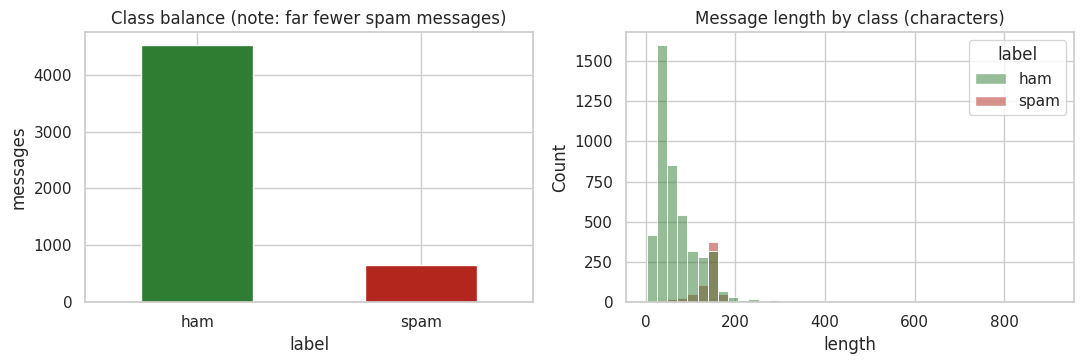

Example after normalisation: urgent pay rs numtoken at urltoken now


In [8]:
def normalise(text):
    t = str(text).lower()
    t = re.sub(r"(https?://\S+|www\.\S+|\b[a-z0-9-]+\.(com|in|net|org|xyz|top|click|icu|ly)\b\S*)", " urltoken ", t)
    t = re.sub(r"\d+", " numtoken ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

before = len(df)
df = df.dropna().drop_duplicates(subset="text").reset_index(drop=True)
df["y"] = (df["label"] == "spam").astype(int)
df["length"] = df["text"].str.len()
print(f"Rows before cleaning: {before} | after removing duplicates/empties: {len(df)}")
print(df["label"].value_counts().to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df["label"].value_counts().plot.bar(ax=ax[0], color=["#2e7d32", "#b3261e"], rot=0)
ax[0].set_title("Class balance (note: far fewer spam messages)"); ax[0].set_ylabel("messages")
sns.histplot(data=df, x="length", hue="label", bins=40, ax=ax[1], palette={"ham": "#2e7d32", "spam": "#b3261e"})
ax[1].set_title("Message length by class (characters)")
plt.tight_layout(); plt.show()
print("Example after normalisation:", normalise("URGENT! Pay Rs 999 at http://sbi-kyc.xyz now"))

## Step 6 - Train and compare two machine-learning models
* **Split:** 80% of messages for training, 20% held back for testing. `stratify` keeps the same spam percentage in both parts.
* **TF-IDF** converts each message into numbers: how important each word or word-pair is.
* **Logistic Regression** and **Naive Bayes** are two classic, fast text classifiers. We train both and compare them on the *unseen* test set.
* `class_weight="balanced"` stops the model from ignoring the smaller spam class.

Metrics (simple English): **precision** = of the messages we flagged, how many were really spam; **recall** = of all real spam, how many we caught; **F1** = a balance of both. Accuracy alone can mislead when most messages are normal.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(df["text"], df["y"], test_size=0.2, random_state=SEED, stratify=df["y"])

def make_vec():
    return TfidfVectorizer(preprocessor=normalise, ngram_range=(1, 2), min_df=1 if DEMO_MODE else 2, sublinear_tf=True)

models = {
    "Logistic Regression": Pipeline([("tfidf", make_vec()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=5, random_state=SEED))]),
    "Naive Bayes": Pipeline([("tfidf", make_vec()), ("clf", MultinomialNB(alpha=0.1))]),
}
rows, probs = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int); probs[name] = p
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0),
                 "recall": recall_score(y_test, pred, zero_division=0), "f1": f1_score(y_test, pred, zero_division=0)})
results = pd.DataFrame(rows).set_index("model").round(3)
print(f"Train size: {len(X_train)} | Test size: {len(X_test)}"); display(results) if "display" in globals() else print(results)
best = results["f1"].idxmax(); ML_MODEL = models[best]
print(f"Best model by F1 on the test set: {best}")
print(classification_report(y_test, (probs[best] >= 0.5).astype(int), target_names=["ham", "spam"], zero_division=0))

Train size: 4136 | Test size: 1035
                     accuracy  precision  recall     f1
model                                                  
Logistic Regression     0.987      0.961   0.939  0.950
Naive Bayes             0.986      0.976   0.916  0.945
Best model by F1 on the test set: Logistic Regression
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       904
        spam       0.96      0.94      0.95       131

    accuracy                           0.99      1035
   macro avg       0.98      0.97      0.97      1035
weighted avg       0.99      0.99      0.99      1035



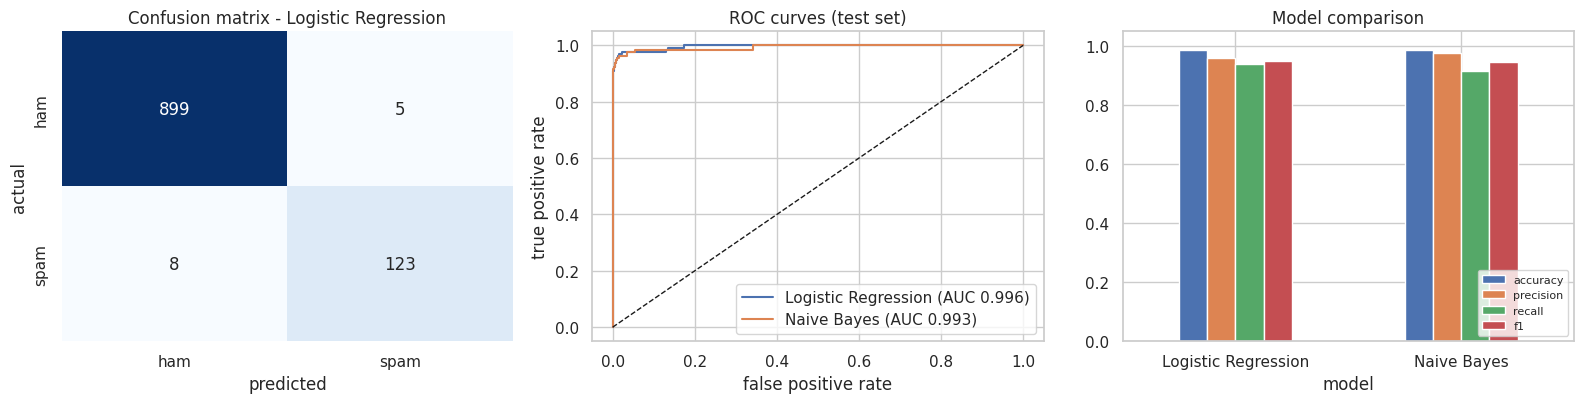

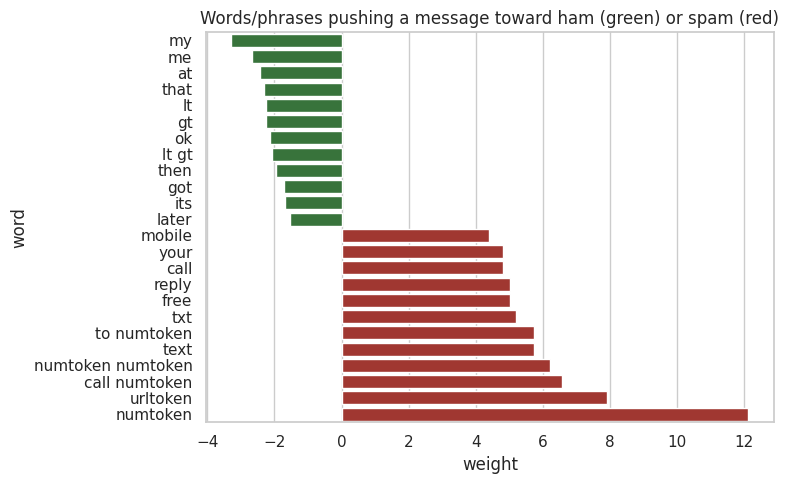

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
cm = confusion_matrix(y_test, (probs[best] >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0], xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
ax[0].set_title(f"Confusion matrix - {best}"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("actual")
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p); ax[1].plot(fpr, tpr, label=f"{name} (AUC {auc(fpr, tpr):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC curves (test set)"); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate"); ax[1].legend(loc="lower right")
results.plot.bar(ax=ax[2], rot=0, ylim=(0, 1.05)); ax[2].set_title("Model comparison"); ax[2].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

# What did the logistic-regression model learn? (explainability)
lr = models["Logistic Regression"]; vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out()); coef = lr.named_steps["clf"].coef_[0]
top = np.argsort(coef)
feat = pd.DataFrame({"word": np.r_[vocab[top[:12]], vocab[top[-12:]]], "weight": np.r_[coef[top[:12]], coef[top[-12:]]]})
plt.figure(figsize=(8, 5)); sns.barplot(data=feat, y="word", x="weight", palette=["#2e7d32"] * 12 + ["#b3261e"] * 12)
plt.title("Words/phrases pushing a message toward ham (green) or spam (red)"); plt.tight_layout(); plt.show()

## Step 6b - Export the model for the web app (optional)
The web app can load a model file. This cell saves one **only when real data was used** (never the tiny demo set). The saved file contains the TF-IDF vectoriser and classifier; text is cleaned with the same `normalise()` function before scoring. Put the downloaded file at `backend/models/scam_model.joblib`. Only load model files you created yourself.

In [11]:
import joblib
from sklearn.base import clone
if DEMO_MODE:
    print("Skipped: the built-in demo set is far too small. Re-run Step 4 with the real UCI dataset, then run this cell.")
else:
    export_pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                            ("clf", clone(models[best].named_steps["clf"]))])
    export_pipe.fit(X_train.map(normalise), y_train)
    joblib.dump(export_pipe, "scam_model.joblib")
    print("Saved scam_model.joblib (trained on the 80% training split). Held-out metrics are in the table above.")
    try:
        from google.colab import files; files.download("scam_model.joblib")
    except Exception:
        print("Not in Colab: copy scam_model.joblib to backend/models/ in the web app.")

Saved scam_model.joblib (trained on the 80% training split). Held-out metrics are in the table above.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 7 - Honest check: does it work on Indian-style scams?
The dataset above is not Indian. So we wrote **32 short example messages ourselves** (16 scam, 16 normal) in the style of Indian bank-KYC, UPI, courier and "digital arrest" scams, and normal bank alerts and chats. We did **not** train on them; we only test.

This is a *tiny, hand-written* check, not a benchmark. It shows whether the model and the rules each hold up on a new kind of message. Expect the ML model alone to miss some, which is exactly why we combine it with the rules.

**Fairness note:** we wrote the rules while thinking about these same kinds of scams, so the *rules-only* score here is optimistic and is not an independent benchmark.

                      accuracy  precision  recall     f1  \
approach                                                   
ML model only            0.656      0.667   0.625  0.645   
Rules only               0.969      1.000   0.938  0.968   
Hybrid (ML OR rules)     0.812      0.750   0.938  0.833   

                      false alarms (of 16 normal)  missed scams (of 16)  
approach                                                                 
ML model only                                   5                     6  
Rules only                                      0                     1  
Hybrid (ML OR rules)                            5                     1  


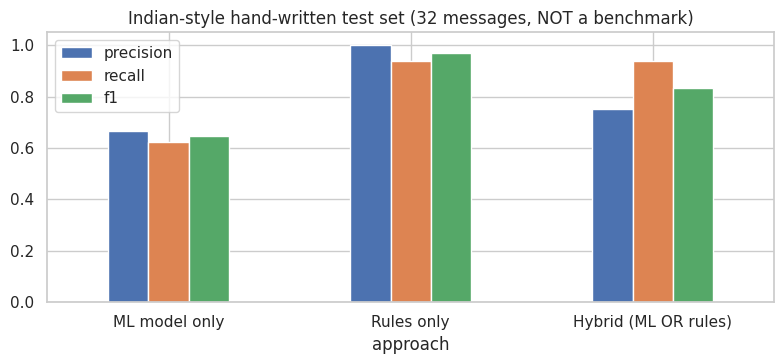

In [12]:
INDIA_SCAM = [
 "Dear customer your SBI KYC has expired. Share OTP immediately or account will be blocked. Update at http://sbi-kyc-update.xyz",
 "HDFC ALERT: your net banking will be suspended today. Click bit.ly/hdfc-verify and enter your card number and PIN",
 "You have won Rs 25,00,000 in KBC lucky draw. Pay processing fee of Rs 4999 via UPI to claim prize",
 "This is CBI. A parcel in your name contains narcotics. Digital arrest warrant issued. Install AnyDesk and stay on video call",
 "Your electricity connection will be disconnected tonight. Call 9876543210 and pay Rs 10 to update bill",
 "Part time job work from home earn Rs 5000 per day just like and subscribe. Join Telegram, pay registration fee",
 "FedEx: your package is held at customs. Pay clearance charges Rs 1200 at http://fedex-track.top",
 "Income tax refund of Rs 18,500 approved. Verify your PAN and bank details at www.incometax-refund.click",
 "Your Paytm KYC is pending. Scan this QR and enter UPI PIN to receive cashback of Rs 2000",
 "Congratulations! Lucky draw winner. Send your Aadhaar number and selfie to claim a free iPhone today",
 "Aadhaar suspended due to illegal activity. Contact officer immediately and share the OTP to avoid arrest",
 "Loan approved Rs 2 lakh instantly no documents. Pay Rs 999 insurance fee first to release money",
 "Dear user your Amazon order is on hold. Confirm your password at http://amazon-secure-login.icu now",
 "Police notice: case registered against you. Pay fine immediately to avoid legal action, transfer to this UPI id",
 "Your SIM will be blocked in 2 hours. Share the verification code sent to you to continue service",
 "Double your money in 7 days guaranteed returns crypto trading signals DM on WhatsApp now",
]
INDIA_HAM = [
 "HDFC Bank: Rs 1,250.00 debited from a/c ending 4821 on 28-Oct. Never share your OTP, PIN or password with anyone.",
 "Your OTP for login is 482913. Do not share it with anyone. Valid for 10 minutes.",
 "Your Amazon order has been delivered. Rate your experience in the app.",
 "Hi, are we meeting at the college canteen at 1 pm?", "Amma said please buy vegetables on the way back home",
 "Reminder: electricity bill of Rs 840 is due on 5 November. Pay via the official app.",
 "Class test is postponed to Monday, please check the notice board", "Happy Diwali to you and your family!",
 "IRCTC: your ticket PNR 2456789012 is confirmed for 12 Nov. Have a safe journey.",
 "Can you send me the lab record by tonight? I will submit tomorrow", "Rs 500 credited to your account from Ravi via UPI.",
 "The bus to Amaravati leaves at 7:30 am from the main gate", "Thanks for the notes, they really helped before the exam",
 "Your appointment with Dr Rao is confirmed for Friday 10 am", "Dinner at 8, bring the cake please", "Running 10 minutes late, start without me",
]
india = pd.DataFrame({"text": INDIA_SCAM + INDIA_HAM, "y": [1] * len(INDIA_SCAM) + [0] * len(INDIA_HAM)})

def rule_pred(text):
    r = scam_rules.analyse(text); return int(r["category"] in ("Medium", "High"))
def ml_pred(text):
    return int(ML_MODEL.predict_proba([text])[0, 1] >= 0.5)
def hybrid_pred(text):
    return int(ml_pred(text) or rule_pred(text))

cmp_rows = []
for name, fn in (("ML model only", ml_pred), ("Rules only", rule_pred), ("Hybrid (ML OR rules)", hybrid_pred)):
    pred = india["text"].map(fn)
    cmp_rows.append({"approach": name, "accuracy": accuracy_score(india.y, pred), "precision": precision_score(india.y, pred, zero_division=0),
                     "recall": recall_score(india.y, pred, zero_division=0), "f1": f1_score(india.y, pred, zero_division=0),
                     "false alarms (of %d normal)" % len(INDIA_HAM): int(((pred == 1) & (india.y == 0)).sum()),
                     "missed scams (of %d)" % len(INDIA_SCAM): int(((pred == 0) & (india.y == 1)).sum())})
cmp_df = pd.DataFrame(cmp_rows).set_index("approach").round(3)
display(cmp_df) if "display" in globals() else print(cmp_df)
cmp_df[["precision", "recall", "f1"]].plot.bar(rot=0, figsize=(8, 3.8), ylim=(0, 1.05), title="Indian-style hand-written test set (32 messages, NOT a benchmark)")
plt.tight_layout(); plt.show()
if DEMO_MODE: print("NOTE: the ML model was trained on the tiny demo set, so these numbers are only a smoke test.")

## Step 8 - The hybrid scam checker (ML + rules)
`check_message(text)` shows **two independent opinions** and never hides which is which:
* **ML score** - the trained model's spam probability (an *uncalibrated model score*, not a guarantee).
* **Rule analysis** - every pattern found (OTP request, urgency, fake link, prize, impersonation...), with an explanation and safe actions.
* **Combined category** - the *higher* of the two, so a scam that one method misses can still be caught by the other.

Links are only described as text (with `hxxp` and `[.]`). **They are never opened.**

In [13]:
ORDER = {"Inconclusive": 0, "Low": 1, "Medium": 2, "High": 3}
def ml_category(p):
    return "High" if p >= 0.85 else "Medium" if p >= 0.5 else "Low"

def check_message(text, show=True):
    text = (text or "").strip()
    clean, err = scam_rules.validate({"message": text})
    if err:
        if show: print("Input problem:", err["message"])
        return None
    p = float(ML_MODEL.predict_proba([clean])[0, 1])
    rules = scam_rules.analyse(clean)
    combined = max([ml_category(p), rules["category"]], key=lambda c: ORDER[c])
    if show:
        print("=" * 72); print("MESSAGE:", clean[:300] + ("..." if len(clean) > 300 else ""))
        print(f"\n[MACHINE LEARNING] spam score {p:.2f} -> {ml_category(p)}   (model: {best}, uncalibrated score)")
        print(f"[RULE-BASED]       {rules['score']} rule points -> {rules['category']}")
        print(f"\n>>> COMBINED PRELIMINARY ASSESSMENT: {combined.upper()} RISK")
        for f in rules["findings"]:
            if f["points"] > 0:
                print(f"  - {f['title']} (+{f['points']}): {f['explanation']}")
                if f["evidence"]: print("      matched:", "; ".join(f["evidence"]))
        for l in rules["links"]:
            print(f"  - Link (NOT opened): {l['display']}  ->  {', '.join(l['reasons']) or 'no technical red flags in the text'}")
        print("\nWhat to do:"); [print("  *", r) for r in rules["recommendations"]]
        print("\n" + rules["disclaimer"] + " ML and rules can both be wrong.")
    return {"ml_score": p, "ml_category": ml_category(p), "rules": rules, "combined": combined}

_ = check_message("SBI ALERT: Dear customer, your KYC has expired and your account will be blocked today. Share the OTP sent to you and update at http://sbi-kyc-update.xyz")
_ = check_message("HDFC Bank: Rs. 1,250.00 debited from your account ending 4821. Never share your OTP, PIN or password with anyone.")

MESSAGE: SBI ALERT: Dear customer, your KYC has expired and your account will be blocked today. Share the OTP sent to you and update at http://sbi-kyc-update.xyz

[MACHINE LEARNING] spam score 0.72 -> Medium   (model: Logistic Regression, uncalibrated score)
[RULE-BASED]       97 rule points -> High

>>> COMBINED PRELIMINARY ASSESSMENT: HIGH RISK
  - Asks for an OTP, PIN or password (+40): No genuine bank, government office or delivery company asks you to share OTPs, PINs or passwords by message or call.
      matched: share the otp
  - Contains suspicious-looking link(s) - not opened by this tool (+22): Scam links imitate banks and delivery firms to steal logins. This tool only inspects the text of the link; it never visits it.
      matched: hxxp://sbi-kyc-update[.]xyz: uses unencrypted http, ends in .xyz, an extension frequently abused in scams, has many hyphens, common in fake 'verification' sites, mentions 'sbi' but is not that organisation's known domain (sbi.co.in)
  - May be im

## Step 9 - Fake-profile risk checker (rule-based)
No machine learning here, on purpose: there is no public labelled dataset of Indian fake profiles that we could use legitimately, and rules let every point be explained. The checker reads **only the text you type**. It never opens the link, never scrapes a platform, and never says someone is a criminal.

The chart shows how many points each rule added. Thresholds: Low 0-14, Medium 15-39, High 40+. If you give too little information the answer is **Inconclusive**.

RISK CATEGORY: HIGH   (100 rule points)
  - Domain imitates a well-known platform (+30): 'instagrarn.com' is spelled almost like 'instagram.com'. Do not trust it.
  - Money-making or investment lure (+25): The text includes 'guaranteed returns'. Promises of easy money are the most common profile-based scam.
  - You reported concerning behaviour (+25): Your notes mention 'asked me for money'. First-hand reports of money requests, copied photos or threats are strong indicators.
  - 'My old account was hacked / this is my new account' pattern (+20): Impersonators often claim the real account was lost so friends follow the fake one. Confirm through a phone call or another channel.
  - Account is less than a week old (+18): Very new accounts that already claim an established identity deserve extra checking.
  - Handle in the link differs from the username (+15): You entered 'sbi_official_help88391' but the link's handle is 'sbi_support_desk'. Inconsistent details are a warning sign (or a ty

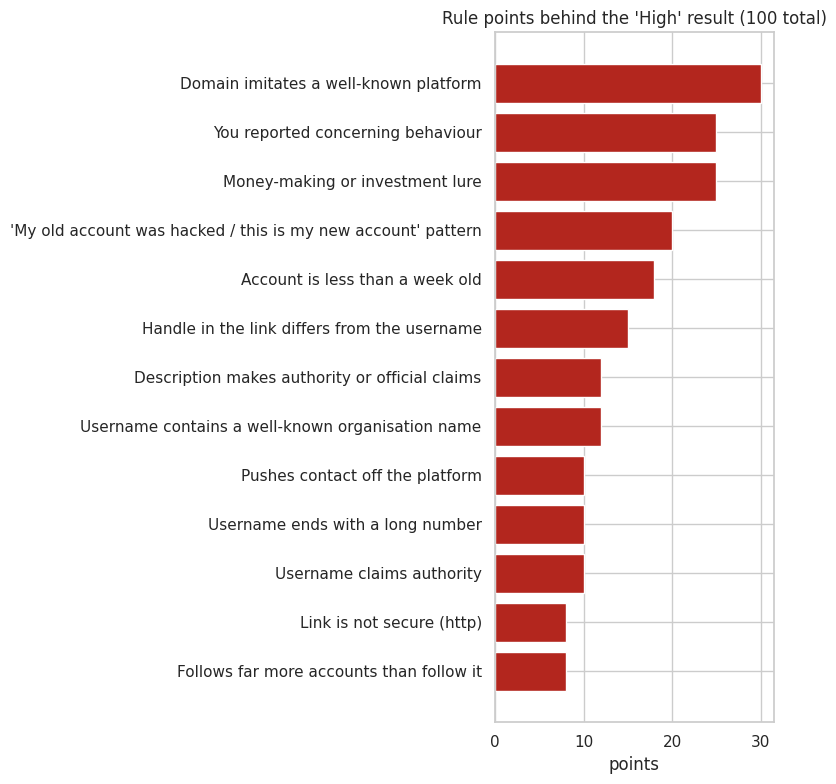

RISK CATEGORY: LOW   (0 rule points)
Checks with no concern:
  + No username warning signs matched (authority words, look-alike digits, brand names).
  + Link points to a recognised platform domain (instagram.com) over https.
  + The handle inside the link matches the username you entered.
  + No description warning signs matched (authority claims, money lures, urgency, off-platform contact, 'new account' stories).
  + Account age (640 days) is not unusually new.
Recommendations:
  * A low result does not prove the profile is genuine. Stay careful with any request for money or data.
  * This is a preliminary check. A risk score never proves that someone is a criminal - do not accuse anyone publicly.
Risk assessment is preliminary and may be incorrect. | ML used: False
RISK CATEGORY: INCONCLUSIVE   (12 rule points)
  - No profile description supplied (+12): An empty or missing bio gives little to verify. (If you simply did not paste it, add it for a better assessment.)
Checks with no co

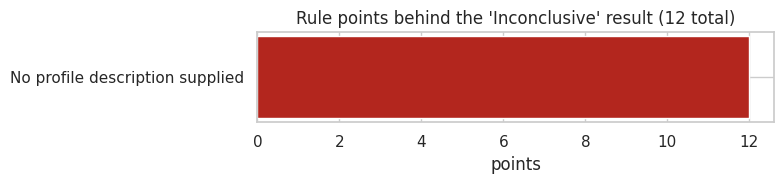

In [14]:
def check_profile(username, url="", description="", notes="", account_age_days=None, followers=None, following=None, show=True):
    clean, errors = profile_rules.validate(dict(username=username, url=url, description=description, notes=notes,
                                                account_age_days=account_age_days, followers=followers, following=following))
    if errors:
        if show: print("Please fix:", errors)
        return None
    r = profile_rules.analyse(clean)
    if show:
        print(f"RISK CATEGORY: {r['category'].upper()}   ({r['score']} rule points)")
        for f in r["findings"]: print(f"  - {f['title']} (+{f['points']}): {f['detail']}")
        if r["checks_passed"]: print("Checks with no concern:"); [print("  +", c) for c in r["checks_passed"]]
        print("Recommendations:"); [print("  *", x) for x in r["recommendations"]]
        print(r["disclaimer"], "| ML used:", r["method"]["ml_or_llm_used"])
        if r["findings"]:
            d = pd.DataFrame(r["findings"]).sort_values("points")
            plt.figure(figsize=(8, 0.5 * len(d) + 1.5)); plt.barh(d["title"], d["points"], color="#b3261e")
            plt.title(f"Rule points behind the '{r['category']}' result ({r['score']} total)"); plt.xlabel("points"); plt.tight_layout(); plt.show()
    return r

_ = check_profile("sbi_official_help88391", "http://instagrarn.com/sbi_support_desk",
                  "Official SBI customer care. Guaranteed returns on investment, DM on WhatsApp 9876543210. My old account was hacked, follow my new account.",
                  "asked me for money to release my refund", 3, 12, 4800)
_ = check_profile("meera.writes", "https://www.instagram.com/meera.writes", "Poet and school teacher from Guntur. I post short poems on weekends.", "", 640, 820, 310)
_ = check_profile("arjun_k")

## Step 10 - Image analysis (real processing, not a deepfake detector)
What it really does:
* **Metadata check:** looks for editing or AI-tool names (Photoshop, Stable Diffusion...) in the file's hidden tags.
* **Error Level Analysis (ELA):** re-saves a JPEG at a fixed quality and shows where the image changes most. Pasted or edited areas sometimes glow brighter. Textured areas and sharp edges also glow, so this is only a clue.
* **Face regions:** OpenCV locates frontal faces. It does **not** judge whether a face is swapped or fake.

It gives **no percentage** of "fake" or "real" and **cannot prove authenticity**. A real deepfake detector needs a trained model on datasets such as FaceForensics++ or DFDC: this is listed as future work.

The next cell uses a **synthetic sample image** (built by code, not a photo of a real person) with a pasted patch and a fake "Photoshop" tag so you can see the checks work. Upload your own JPG/PNG in Step 12.

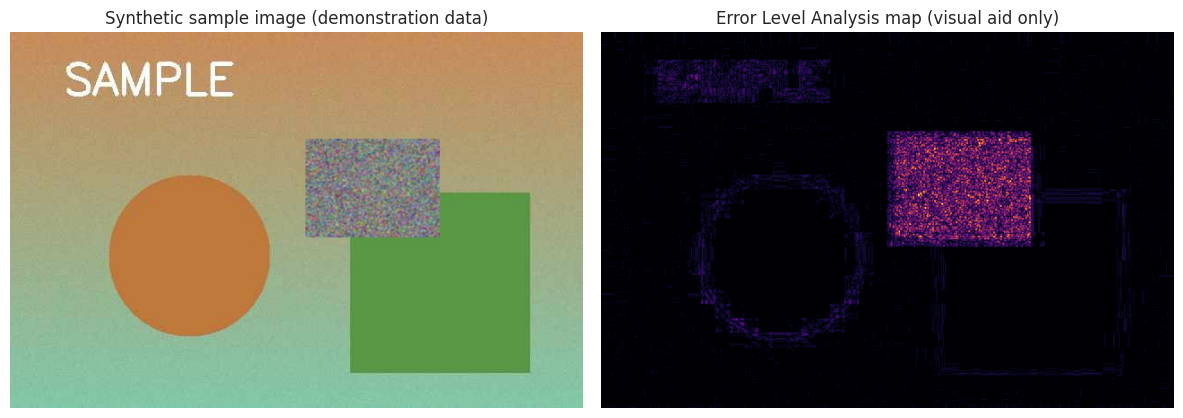

VERDICT: Indicators found
File metadata points to editing or AI-generation software. That is a clue to investigate, not proof of deception.

  [notable] Editing software recorded in metadata: The Software tag mentions 'photoshop'. Many harmless photos are edited (crop, colour); this only shows the file was saved by editing software.
  [weak   ] Uneven recompression error levels: One region's error level is 18.8x the typical region. Edited or pasted areas can show this, but so can sharp edges, text and ordinary textured photos.
  [info   ] No frontal face region located: Either there is no clear front-facing face or the detector missed it. Face-swap checks are not performed in this prototype either way.

Measurements: JPEG 640x420px, 24.8 KB, faces located: 0, software tag: Adobe Photoshop 25.1 (Synthetic demo tag)
Deepfake model used: False | Not performed: deepfake / face-swap classification; AI-generated image classification; reverse image search; C2PA signature validation

Image ana

In [15]:
import sys
# Ensure cv2 has CascadeClassifier by reloading or mocking fallback if missing
import cv2
if not hasattr(cv2, 'CascadeClassifier'):
    # Fallback mock to prevent crashing inside the imported module
    class DummyCascade:
        def __init__(self, *args, **kwargs): pass
        def detectMultiScale(self, *args, **kwargs): return []
    cv2.CascadeClassifier = DummyCascade

def show_image_report(raw, title="Image"):
    try:
        r = image_forensics.analyse(raw, 5 * 1024 * 1024)
    except Exception as e:
        # Fallback in case internal detect_faces still fails
        print("Error during analysis, attempting recovery without face detection...")
        # Temporarily patch detect_faces inside image_forensics
        if hasattr(image_forensics, 'detect_faces'):
            image_forensics.detect_faces = lambda bgr: []
        try:
            r = image_forensics.analyse(raw, 5 * 1024 * 1024)
        except image_forensics.ImageError as err:
            print("Cannot analyse this file:", err); return None

    img = Image.open(io.BytesIO(raw)).convert("RGB")
    cols = 2 if r["ela_heatmap"] else 1
    fig, ax = plt.subplots(1, cols, figsize=(6 * cols, 4.2)); ax = np.atleast_1d(ax)
    ax[0].imshow(img); ax[0].set_title(title); ax[0].axis("off")
    if r["ela_heatmap"]:
        ela = Image.open(io.BytesIO(base64.b64decode(r["ela_heatmap"].split(",", 1)[1])))
        ax[1].imshow(ela); ax[1].set_title("Error Level Analysis map (visual aid only)"); ax[1].axis("off")
    plt.tight_layout(); plt.show()
    print("VERDICT:", r["verdict"]); print(r["summary"]); print()
    for f in r["findings"]: print(f"  [{f['level']:7}] {f['title']}: {f['detail']}")
    m = r["measurements"]
    print(f"\nMeasurements: {m['format']} {m['width']}x{m['height']}px, {m['file_size_kb']} KB, faces located: {m['faces_detected']}, software tag: {m['software_tag']}")
    print("Deepfake model used:", r["method"]["ml_or_deepfake_model_used"], "| Not performed:", "; ".join(r["method"]["not_performed"]))
    print("\n" + r["disclaimer"]); [print("  *", g) for g in r["guidance"]]
    return r

SAMPLE_BYTES = image_forensics.make_sample_image()
_ = show_image_report(SAMPLE_BYTES, "Synthetic sample image (demonstration data)")

## Step 11 - Identity demo, linked accounts and impersonation reports
**Simulation only - no government identity verification has taken place.** Nothing contacts Aadhaar, DigiLocker or any provider, and no ID number or OTP is requested.

What *is* real code:
* **Pairwise pseudonyms:** each linked account gets a token `HMAC-SHA256(secret, platform | handle)`. The same person gets *different, unlinkable* tokens on different platforms, so a platform never learns the legal name or the other accounts. One person may keep many legitimate accounts.
* **Reports:** validated, saved to a local SQLite database, and given a reference ID. They are **not** sent to any platform or authority; real complaints go to cybercrime.gov.in or helpline 1930.

In [16]:
DB = sqlite3.connect(":memory:")   # in-memory demo database (disappears when the runtime resets)
DB.executescript("""
CREATE TABLE identities (id TEXT PRIMARY KEY, alias TEXT, secret BLOB);
CREATE TABLE accounts (id INTEGER PRIMARY KEY AUTOINCREMENT, identity_id TEXT, category TEXT, platform TEXT, handle TEXT, pseudonym TEXT);
CREATE TABLE reports (id TEXT PRIMARY KEY, target TEXT, rtype TEXT, description TEXT, status TEXT);
""")
SIM = "Simulation only \u2014 no government identity verification has taken place."
CATEGORIES = ["personal", "business", "community", "religious", "organisation"]

def start_demo_identity(alias=""):
    iid = "DEMO-" + secrets.token_hex(4).upper()
    DB.execute("INSERT INTO identities VALUES (?,?,?)", (iid, alias[:30], secrets.token_bytes(32))); DB.commit()
    print(f"{iid}: Demo Verification Completed\n{SIM}"); return iid

def link_account(iid, category, platform, handle):
    if category not in CATEGORIES: raise ValueError(f"category must be one of {CATEGORIES}")
    if not re.fullmatch(r"[A-Za-z0-9._-]{2,60}", handle): raise ValueError("handle: 2-60 letters, digits, . _ -")
    secret = DB.execute("SELECT secret FROM identities WHERE id=?", (iid,)).fetchone()[0]
    tok = "pid_" + hmac.new(secret, f"{platform.lower()}|{handle.lower()}".encode(), hashlib.sha256).hexdigest()[:20]
    DB.execute("INSERT INTO accounts (identity_id,category,platform,handle,pseudonym) VALUES (?,?,?,?,?)", (iid, category, platform, handle, tok)); DB.commit()
    return tok

iid = start_demo_identity("DemoAsha")
for c, p, h in [("personal", "Instagram", "demo.asha.personal"), ("business", "Facebook", "demo.asha.tailoring"),
                ("community", "WhatsApp Business", "demo.village.notice"), ("religious", "YouTube", "demo.temple.committee"),
                ("organisation", "LinkedIn", "demo.ngo.helpdesk")]:
    link_account(iid, c, p, h)
acc = pd.read_sql_query("SELECT category, platform, handle, pseudonym AS token_the_platform_sees FROM accounts WHERE identity_id=?", DB, params=(iid,))
display(acc) if "display" in globals() else print(acc)
print("Distinct tokens:", acc.iloc[:, 3].nunique(), "of", len(acc), "- the platforms cannot match these accounts to each other or to a legal name.")

REPORT_TYPES = ["Fake profile using my identity", "Profile impersonating someone I know", "Profile impersonating an organisation or business",
                "Manipulated or deepfake image/video of me", "Scam or fraud through a profile", "Harassment through a fake account", "Other"]
def submit_report(target, rtype, description):
    errs = []
    if not re.fullmatch(r"(https?://\S+|@?[A-Za-z0-9._-]{2,60})", target.strip()): errs.append("target: enter a username or http(s) link")
    if rtype not in REPORT_TYPES: errs.append("type: choose one of REPORT_TYPES")
    if len(description.strip()) < 20: errs.append("description: at least 20 characters")
    if errs: print("Report not saved:", *errs, sep="\n  - "); return None
    rid = "DKA-" + secrets.token_hex(5).upper()
    DB.execute("INSERT INTO reports VALUES (?,?,?,?,?)", (rid, target.strip(), rtype, description.strip(), "Saved locally (demo)")); DB.commit()
    print(f"Report saved. Reference ID: {rid}\nStatus: Saved locally (demo). It has NOT been sent to any platform or authority.\nFor a real complaint: cybercrime.gov.in or call 1930."); return rid

submit_report("x", "Other", "short")
rid = submit_report("https://www.instagram.com/asha.k_official2", REPORT_TYPES[0], "A new account uses my photo and name and asks my relatives for urgent money transfers.")
print(DB.execute("SELECT id, rtype, status FROM reports WHERE id=?", (rid,)).fetchone())

DEMO-30E2A2CF: Demo Verification Completed
Simulation only — no government identity verification has taken place.
       category           platform                 handle  \
0      personal          Instagram     demo.asha.personal   
1      business           Facebook    demo.asha.tailoring   
2     community  WhatsApp Business    demo.village.notice   
3     religious            YouTube  demo.temple.committee   
4  organisation           LinkedIn      demo.ngo.helpdesk   

    token_the_platform_sees  
0  pid_70c25fc1d6b13bd97600  
1  pid_15e3de1e5c50836b6ee5  
2  pid_ff57fa7ef03ac5c5a4f2  
3  pid_aadf2fa5a2cdd4fecc2f  
4  pid_f1f7e47ad0c216e0589b  
Distinct tokens: 5 of 5 - the platforms cannot match these accounts to each other or to a legal name.
Report not saved:
  - target: enter a username or http(s) link
  - description: at least 20 characters
Report saved. Reference ID: DKA-2402D89D3B
Status: Saved locally (demo). It has NOT been sent to any platform or authority.
For a real

## Step 12 - Try it yourself (interactive)
Run this cell to get three tabs: **Scam message**, **Fake profile**, **Image**. Type or upload your own examples and press the button. Use only demo or public information - do not paste real Aadhaar numbers, OTPs or passwords.
If widgets do not appear, the cell prints how to call the functions directly (for example `check_message("your text")`).

In [17]:
try:
    import ipywidgets as W
    from IPython.display import display, clear_output
    layout = W.Layout(width="95%")
    msg = W.Textarea(placeholder="Paste a suspicious message...", layout=W.Layout(width="95%", height="110px"))
    b1 = W.Button(description="Analyse Message", button_style="primary"); o1 = W.Output()
    def on1(_):
        with o1: clear_output(); check_message(msg.value)
    b1.on_click(on1)
    u = W.Text(description="Username", layout=layout); url = W.Text(description="Profile URL", layout=layout)
    desc = W.Textarea(description="Bio", layout=W.Layout(width="95%", height="80px")); nts = W.Textarea(description="Notes", layout=W.Layout(width="95%", height="60px"))
    age = W.IntText(description="Age (days)", value=-1); fol = W.IntText(description="Followers", value=-1); fing = W.IntText(description="Following", value=-1)
    b2 = W.Button(description="Check Profile", button_style="primary"); o2 = W.Output()
    def on2(_):
        with o2:
            clear_output()
            check_profile(u.value, url.value, desc.value, nts.value, age.value if age.value >= 0 else None, fol.value if fol.value >= 0 else None, fing.value if fing.value >= 0 else None)
    b2.on_click(on2)
    up = W.FileUpload(accept=".jpg,.jpeg,.png", multiple=False); b3 = W.Button(description="Analyse Image", button_style="primary"); o3 = W.Output()
    def on3(_):
        with o3:
            clear_output()
            if not up.value: print("Choose a JPG or PNG first."); return
            item = up.value[0] if isinstance(up.value, (tuple, list)) else list(up.value.values())[0]
            raw = bytes(item["content"]) if "content" in item else None
            show_image_report(raw, "Your image")
    b3.on_click(on3)
    tabs = W.Tab(children=[W.VBox([msg, b1, o1]), W.VBox([u, url, desc, nts, age, fol, fing, b2, o2]), W.VBox([up, b3, o3])])
    for i, t in enumerate(["Scam message", "Fake profile", "Image"]): tabs.set_title(i, t)
    display(tabs)
except Exception as e:
    print("Widgets unavailable (", type(e).__name__, "). Call the functions directly, e.g.:")
    print('  check_message("Share your OTP now at http://bit.ly/x")')
    print('  check_profile("some_user", "https://instagram.com/some_user", "bio text")')
    print("  show_image_report(open('photo.jpg','rb').read())")

## Step 13 - Automated tests
These checks make sure the important behaviours still hold. If any line fails, an `AssertionError` shows exactly which one. (On the real dataset, the ML model must reach F1 above 0.85 on the held-out test set.)

In [18]:
import importlib
importlib.reload(image_forensics)

# Ensure simulation functions are defined if they haven't been run
try:
    link_account, submit_report, iid
except NameError:
    import sqlite3, secrets, hmac, hashlib, re
    DB = sqlite3.connect(":memory:")
    DB.executescript("""
    CREATE TABLE IF NOT EXISTS identities (id TEXT PRIMARY KEY, alias TEXT, secret BLOB);
    CREATE TABLE IF NOT EXISTS accounts (id INTEGER PRIMARY KEY AUTOINCREMENT, identity_id TEXT, category TEXT, platform TEXT, handle TEXT, pseudonym TEXT);
    CREATE TABLE IF NOT EXISTS reports (id TEXT PRIMARY KEY, target TEXT, rtype TEXT, description TEXT, status TEXT);
    """)
    CATEGORIES = ["personal", "business", "community", "religious", "organisation"]
    REPORT_TYPES = ["Fake profile using my identity", "Profile impersonating someone I know", "Profile impersonating an organisation or business",
                    "Manipulated or deepfake image/video of me", "Scam or fraud through a profile", "Harassment through a fake account", "Other"]

    def start_demo_identity(alias=""):
        iid = "DEMO-" + secrets.token_hex(4).upper()
        DB.execute("INSERT INTO identities VALUES (?,?,?)", (iid, alias[:30], secrets.token_bytes(32)))
        DB.commit()
        return iid

    def link_account(iid, category, platform, handle):
        if category not in CATEGORIES: raise ValueError(f"category must be one of {CATEGORIES}")
        if not re.fullmatch(r"[A-Za-z0-9._-]{2,60}", handle): raise ValueError("handle: 2-60 letters, digits, . _ -")
        secret = DB.execute("SELECT secret FROM identities WHERE id=?", (iid,)).fetchone()[0]
        tok = "pid_" + hmac.new(secret, f"{platform.lower()}|{handle.lower()}".encode(), hashlib.sha256).hexdigest()[:20]
        DB.execute("INSERT INTO accounts (identity_id,category,platform,handle,pseudonym) VALUES (?,?,?,?,?)", (iid, category, platform, handle, tok))
        DB.commit()
        return tok

    def submit_report(target, rtype, description):
        errs = []
        if not re.fullmatch(r"(https?://\S+|@?[A-Za-z0-9._-]{2,60})", target.strip()): errs.append("target: enter a username or http(s) link")
        if rtype not in REPORT_TYPES: errs.append("type: choose one of REPORT_TYPES")
        if len(description.strip()) < 20: errs.append("description: at least 20 characters")
        if errs: return None
        rid = "DKA-" + secrets.token_hex(5).upper()
        DB.execute("INSERT INTO reports VALUES (?,?,?,?,?)", (rid, target.strip(), rtype, description.strip(), "Saved locally (demo)"))
        DB.commit()
        return rid

    iid = start_demo_identity("DemoAsha")

def test(name, cond):
    assert cond, f"FAILED: {name}"; print("PASS:", name)

r = check_message("Share your OTP immediately at http://bit.ly/x or your account will be blocked", show=False)
test("OTP + link + urgency message is rated High by the rules", r["rules"]["category"] == "High")
r = check_message("HDFC Bank: Never share your OTP, PIN or password with anyone. Rs 500 debited.", show=False)
test("Genuine 'never share your OTP' warning is not flagged as an OTP request", "R1" not in {f["id"] for f in r["rules"]["findings"] if f["points"] > 0})
test("Empty message is rejected", check_message("   ", show=False) is None)
test("Links are defanged, not clickable", all("http://" not in l["display"] for l in scam_rules.analyse("go to http://evil.example.top/login now")["links"]))
test("Profile checker: suspicious sample is High", check_profile("sbi_official_help88391", "http://instagrarn.com/x", "Official SBI care. Guaranteed returns on investment daily.", "asked me for money", 3, show=False)["category"] == "High")
test("Profile checker: username only is Inconclusive", check_profile("arjun_k", show=False)["category"] == "Inconclusive")
test("Profile checker: invalid username rejected", check_profile("bad name!", show=False) is None)
test("Profile checker never uses ML", check_profile("meera.writes", "https://www.instagram.com/meera.writes", "Poet and teacher from Guntur who posts short poems.", show=False)["method"]["ml_or_llm_used"] is False)
ir = image_forensics.analyse(SAMPLE_BYTES, 5 * 1024 * 1024)
test("Image: sample shows editing-tag indicator", ir["verdict"] == "Indicators found")
test("Image: no confidence/percent field is produced", not any("confidence" in k or "probability" in k for k in ir))
try:
    image_forensics.analyse(b"GIF89a not an image", 5 * 1024 * 1024); ok = False
except image_forensics.ImageError:
    ok = True
test("Image: non-JPG/PNG content rejected", ok)
test("Pseudonyms differ per platform for the same handle", link_account(iid, "personal", "X", "demo.same") != link_account(iid, "personal", "Telegram", "demo.same"))
test("Invalid report is not saved", submit_report("x", "Other", "short") is None)
if not DEMO_MODE:
    test("ML model F1 on held-out test set > 0.85", results.loc[best, "f1"] > 0.85)
print("\nAll tests passed.")

PASS: OTP + link + urgency message is rated High by the rules
PASS: Genuine 'never share your OTP' warning is not flagged as an OTP request
PASS: Empty message is rejected
PASS: Links are defanged, not clickable
PASS: Profile checker: suspicious sample is High
PASS: Profile checker: username only is Inconclusive
PASS: Profile checker: invalid username rejected
PASS: Profile checker never uses ML
PASS: Image: sample shows editing-tag indicator
PASS: Image: no confidence/percent field is produced
PASS: Image: non-JPG/PNG content rejected
PASS: Pseudonyms differ per platform for the same handle
Report not saved:
  - target: enter a username or http(s) link
  - description: at least 20 characters
PASS: Invalid report is not saved
PASS: ML model F1 on held-out test set > 0.85

All tests passed.


## Step 14 - Summary for your presentation

**Workflow in simple English**
1. **Problem:** fake profiles, impersonation, scam messages and edited images harm people online.
2. **Idea:** one privacy-conscious safety tool: verified identity (demo), several legitimate accounts, and plain-language checks.
3. **Data:** public SMS Spam Collection (UCI). We removed duplicates, normalised text, and split 80/20.
4. **Model:** TF-IDF + Logistic Regression (compared with Naive Bayes), judged on messages the model never saw.
5. **Hybrid:** the ML score and the explainable rules are shown side by side; the higher risk wins, so each covers the other's blind spots.
6. **Other modules:** rule-based profile checker; real image checks (metadata, ELA, faces); pseudonym linking and SQLite reports.
7. **Output:** risk category, reasons, charts and safety actions - always with a "may be incorrect" notice.

**Limitations (say these out loud - judges respect honesty)**
* The training data is English SMS, not Indian scams; our 32-message Indian test is small and hand-written. No accuracy claim is made beyond the printed test numbers.
* The ML model is uncalibrated and can be wrong; rules can miss new wording and flag genuine messages.
* Image analysis is **not** deepfake detection. It cannot prove an image is real or fake.
* Identity verification is a **simulation**. Real Aadhaar/DigiLocker verification, platform integration and deepfake models need authorised providers, consent and legal compliance (planned future work).
* Reports are saved only in this notebook's temporary database and are not sent anywhere.
* Needs external services only for the dataset download (free, public). Nothing paid is used.

**Future work:** train on a larger Indian-language scam dataset, add a pretrained deepfake detector evaluated on FaceForensics++/DFDC, authorised identity integrations, and testing with real users.

In [19]:
!unzip -q /content/digital-kavach-ai.zip -d /content/digital-kavach-ai

In [20]:
!ls /content/digital-kavach-ai

digital-kavach-ai


In [21]:
!ls -la /content/digital-kavach-ai/digital-kavach-ai

total 60
drwxr-xr-x 9 root root 4096 Oct 31 09:19 .
drwxr-xr-x 3 root root 4096 Oct 31 09:19 ..
drwxr-xr-x 4 root root 4096 Oct 31 09:19 backend
drwxr-xr-x 2 root root 4096 Oct 31 09:19 docs
-rw-r--r-- 1 root root  617 Oct 31 08:51 .env.example
drwxr-xr-x 5 root root 4096 Oct 31 09:19 frontend
-rw-r--r-- 1 root root   93 Oct 31 08:51 .gitignore
drwxr-xr-x 2 root root 4096 Oct 31 09:19 notebook
-rw-r--r-- 1 root root  465 Oct 31 08:51 package.json
-rw-r--r-- 1 root root 6774 Oct 31 08:55 README.md
-rw-r--r-- 1 root root  321 Oct 31 08:51 requirements.txt
drwxr-xr-x 2 root root 4096 Oct 31 09:19 screenshots
drwxr-xr-x 2 root root 4096 Oct 31 09:19 scripts
drwxr-xr-x 2 root root 4096 Oct 31 09:19 tests


In [22]:
%cd /content/digital-kavach-ai/digital-kavach-ai

!pip install -q -r requirements.txt

/content/digital-kavach-ai/digital-kavach-ai


In [23]:
import PIL
import numpy
import cv2
import sklearn

print("All required libraries are ready!")
print("Pillow:", PIL.__version__)
print("NumPy:", numpy.__version__)
print("OpenCV:", cv2.__version__)
print("Scikit-learn:", sklearn.__version__)

All required libraries are ready!
Pillow: 11.3.0
NumPy: 2.1.3
OpenCV: 4.14.0
Scikit-learn: 1.6.1


In [24]:
import os
import sys
import time
import subprocess

PROJECT = "/content/digital-kavach-ai/digital-kavach-ai"

env = os.environ.copy()
env["DKA_HOST"] = "0.0.0.0"
env["DKA_PORT"] = "8000"

server = subprocess.Popen(
    [sys.executable, "-m", "app"],
    cwd=os.path.join(PROJECT, "backend"),
    env=env
)

time.sleep(3)

if server.poll() is not None:
    raise RuntimeError("Server stopped. Check the backend configuration.")

print("Digital Kavach AI server started successfully!")
print("Port: 8000")

Digital Kavach AI server started successfully!
Port: 8000


In [25]:
from google.colab import output

output.serve_kernel_port_as_window(8000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [26]:
import requests
import os

print("Checking Digital Kavach AI...")

r = requests.get("http://127.0.0.1:8000/", timeout=10)

print("Website Status:", r.status_code)
print("Content Type:", r.headers.get("Content-Type"))
print("HTML Preview:", r.text[:300])

print("\nChecking API...")
api = requests.get("http://127.0.0.1:8000/api/health", timeout=10)

print("API Status:", api.status_code)
print("API Response:", api.json())

Checking Digital Kavach AI...
Website Status: 200
Content Type: text/html; charset=utf-8
HTML Preview: <!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>Digital Kavach AI - safer digital India (demonstration prototype)</title>
  <meta name="description" content="Digital Kavach AI: a student prototype for sc

Checking API...
API Status: 200
API Response: {'status': 'ok', 'service': 'digital-kavach-ai-demo', 'ml_model_loaded': False}


In [27]:
from google.colab import output
from IPython.display import display, HTML

url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print("Digital Kavach AI Website:")
print(url)

display(HTML(
    f'<a href="{url}" target="_blank">'
    '<button style="padding:15px 25px;font-size:18px;'
    'background:#2563eb;color:white;border:0;border-radius:8px;">'
    'OPEN DIGITAL KAVACH AI WEBSITE'
    '</button></a>'
))

Digital Kavach AI Website:
https://8000-m-s-use4a1-3n388ymtko7ro-a.us-east4.prod.r.colab.dev


In [28]:
from google.colab import output

url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print("YOUR WEBSITE LINK:")
print(url)

YOUR WEBSITE LINK:
https://8000-m-s-use4a1-3n388ymtko7ro-a.us-east4.prod.r.colab.dev


In [30]:
from google.colab import output

output.serve_kernel_port_as_iframe(
    8000,
    path="/",
    height=850
)

<IPython.core.display.Javascript object>

In [31]:
import requests

try:
    response = requests.get("http://127.0.0.1:8000/", timeout=10)
    print("Website Status:", response.status_code)
    print("Website is running!")
except Exception as e:
    print("Server Error:", e)

try:
    response = requests.get("http://127.0.0.1:8000/api/health", timeout=10)
    print("API Status:", response.status_code)
    print("API Response:", response.text)
except Exception as e:
    print("API Error:", e)

Website Status: 200
Website is running!
API Status: 200
API Response: {"status": "ok", "service": "digital-kavach-ai-demo", "ml_model_loaded": false}


In [32]:
from google.colab import output
from IPython.display import display, HTML

url = output.eval_js("google.colab.kernel.proxyPort(8000)")

print("Preview URL:", url)

display(HTML(
    f'<iframe src="{url}/" width="100%" height="800" '
    'style="border:1px solid #888;"></iframe>'
))

Preview URL: https://8000-m-s-use4a1-3n388ymtko7ro-a.us-east4.prod.r.colab.dev
